In [1]:
# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.io import loadmat
import glob
import h5py
from scipy.stats import pearsonr
import torch
from torch import nn
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import binned_statistic, wilcoxon
import pandas as pd
import pickle
import re
from datetime import datetime
import seaborn as sns

import os
import sys
sys.path.append(os.path.expanduser('~/Documents/code/utils'))
from plotting import plot_stars

# sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat')) 
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.glm import Bat_GLM
from digitalbat.models.layers import ELU1, TransformerEncoderRoPE
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import auprc_per_unit, corr, interpolate_signal_with_nans, lowpass_filter, \
                                    corr, poisson_fraction_deviance_explained, poisson_fde_population, generate_2d_rate_map
from digitalbat.utility.utils import set_random_state, plot_2d_rate_map, plot_2d_trajectory_response, plot_2d_trajectory_response_multiple, \
                                    plot_3d_trajectory, resample_response, nearest_neighbor_score, OrthogonalityPermutationTest
from digitalbat.datasets.data import Data_Prep_for_Raw, bat_data_loader
from digitalbat.utility.interpreter import Saliency, PermutationImportance, ActivationMaximization, ShapAnalysis, Gradient_Bat_Transformer # IntegGradi
from digitalbat.utility.TrajectoryRF import Generate_Synthetic_Trajecories, Time_Resolved_TRF, Time_Resolved_Phase, Trajectory_Level_TRF

In [2]:
seed = 1
set_random_state(seed)

device = 'cuda'

# Dataloader

In [50]:
# recorded data
session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209', # only 9 flight trajectory types
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',  # only ~50 units
    ]

data_config = dict(
    use_speed_head_dir = False, # False
    use_IMU_flag = False,  # False
    use_click_flag = False, # False
    use_LFP_flag = False,  # False
    use_ripple_flag = False,
    only_flight_flag = True,  # True
    no_3d_location = False, # False
    spike_count_flag = True,
    bin_width = 0.10, # 0.10, in seconds
    split_flights_for_train = 'random', # the way to split flight paths for train + valid + test; either 'manual' or 'random'
    type_train_num = 1,  # 1; for splitting flight clustering data
    type_valid_num = 1,  # 1; for splitting flight clustering data
    special_id_count_thresh = 3,  # 3; for splitting flight clustering data
    only_use_special_id_4train_flag = False,  # False
    shuffle_flag = True, # False; shuffle the training data
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False, # False
    split_each_trajectory_flag = True,  # True
    window_size = None, # 20, None; for splitting each trajectory into multiple samples
    stride_train = None, # 20, None; splitting each trajectory into multiple samples, for training data
    stride_test = None, # 20, None; splitting each trajectory into multiple samples, for test data
    batch_size_train = None, # None;
    batch_size_test = None, # None;
    session_names = session_names,
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
    max_acceleration = 50, # in m/s^2; for filtering out artifacts in the data
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)

dataloaders, behavior_dim, unit_num_dict

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)


({'train': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x72c34ed98950>,
   'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x72c32d47f750>,
   'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x72c32d47f650>,
   'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x72c3063b8650>,
   'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x72c3063b8950>,
   'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x72c3063b8c50>,
   'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x72c3063b8f50>,
   'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x72c3063b9250>,
   'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x72c3063b9550>,
   'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x72c3063b9850>},
  'valid': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x72c32d47fb50>,
  

In [4]:
for session_name, session_data in dataloaders['train'].items():
    print(session_name, session_data)
    for batch_id, batch in enumerate(session_data):
        if not data_config['split_each_trajectory_flag']:
            print(batch[0].shape, batch[1].shape) # (N, behavior_feature), (N, spiking_unit_number)
        else:
            # behavior (N, window_size, behavior_feature), spike (N, window_size, spiking_unit_number), mask (N, window_size)
            print(batch[0].shape, batch[1].shape, batch[2].shape, np.sum(batch[2].detach().cpu().numpy()*1.0)) 

Dataset_3_14543_240419 <torch.utils.data.dataloader.DataLoader object at 0x72c3551116a0>
torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119]) 854.0
Dataset_3_14543_240420 <torch.utils.data.dataloader.DataLoader object at 0x72c35514d480>
torch.Size([94, 61, 3]) torch.Size([94, 61, 126]) torch.Size([94, 61]) 2303.0
Dataset_3_14543_240421 <torch.utils.data.dataloader.DataLoader object at 0x72c48424ecf0>
torch.Size([78, 61, 3]) torch.Size([78, 61, 100]) torch.Size([78, 61]) 1964.0
Dataset_3_29959_240402 <torch.utils.data.dataloader.DataLoader object at 0x72c35511ac50>
torch.Size([101, 81, 3]) torch.Size([101, 81, 317]) torch.Size([101, 81]) 3172.0
Dataset_3_29959_240403 <torch.utils.data.dataloader.DataLoader object at 0x72c35511b150>
torch.Size([88, 73, 3]) torch.Size([88, 73, 191]) torch.Size([88, 73]) 2430.0
Dataset_3_29959_240404 <torch.utils.data.dataloader.DataLoader object at 0x72c35511b650>
torch.Size([54, 65, 3]) torch.Size([54, 65, 190]) torch.Size([54, 65]) 

In [5]:
tier = 'train'
session_name = list(dataloaders[tier].keys())[0]
for ii, batch in enumerate(dataloaders[tier][session_name]):
    if not data_config['split_each_trajectory_flag']:
        print(batch[0].shape, batch[1].shape) 
    else:
        print(batch[0].shape, batch[1].shape, batch[2].shape) # torch.Size([61, 20, 3]) torch.Size([61, 20, 289]) torch.Size([61, 20])
# get the elements at real timesteps
tempbeha = batch[0].detach().cpu().numpy()
tempspik = batch[1].detach().cpu().numpy()
tempmask = batch[2].detach().cpu().numpy()
print(tempbeha.shape, tempspik.shape) # (61, 20, 3) (61, 20, 289)
tempbeha = tempbeha[tempmask ==1]
tempspik = tempspik[tempmask ==1]
print(tempbeha.shape, tempspik.shape) # (981, 3) (981, 289)

torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119])
(25, 119, 3) (25, 119, 289)
(854, 3) (854, 289)


In [6]:
batch._fields, batch.flight_path_index, batch.flight_type_index

(('behavior', 'spike', 'mask', 'flight_path_index', 'flight_type_index'),
 tensor([15., 13., 26., 34.,  2.,  3., 21., 19., 25., 18.,  9., 23., 33., 30.,
          8., 35., 22.,  0., 24., 11.,  6., 28., 14.,  7., 16.]),
 tensor([ 7.,  5., 10., 19.,  2.,  3.,  9.,  9., 10.,  9.,  3.,  9., 18., 15.,
          3., 20.,  9.,  1.,  9.,  3.,  3., 12.,  6.,  3.,  8.]))

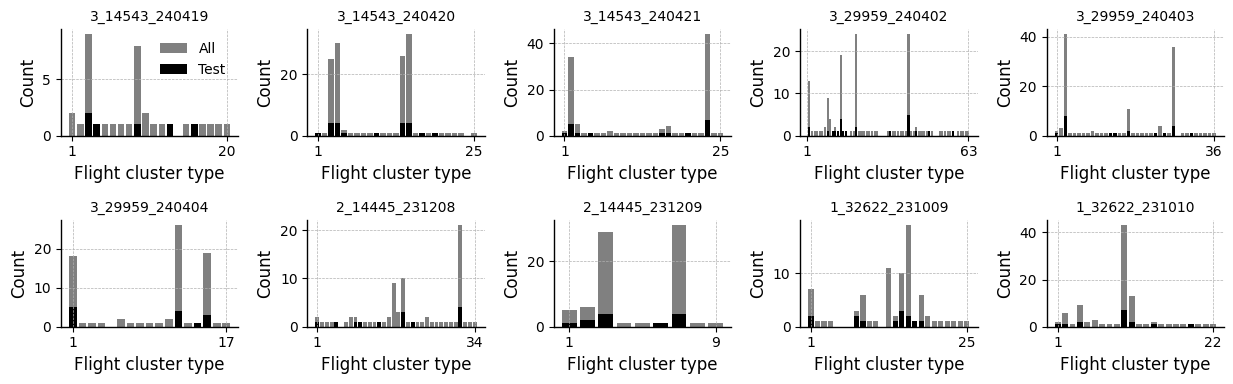

In [7]:
# summarize the flight cluster type distribution
session_names = list(dataloaders['test'].keys())
ncols = 5
nrows = len(session_names) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        flight_type_train = dataloaders['train'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_valid = dataloaders['valid'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_test = dataloaders['test'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type = np.concatenate((flight_type_train, flight_type_valid, flight_type_test))
        unique_vals, counts = np.unique(flight_type, return_counts=True)
        unique_vals_test, counts_test = np.unique(flight_type_test, return_counts=True)
        axes[ii,jj].bar(unique_vals, counts, color='gray', label='All')
        axes[ii,jj].bar(unique_vals_test, counts_test, color='k', label='Test')
        axes[ii,jj].set_xticks([1, unique_vals.max()])
        axes[ii,jj].set_xlabel("Flight cluster type")
        axes[ii,jj].set_ylabel("Count")
        axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
axes[0,0].legend(loc='best',frameon=False)
plt.tight_layout()

# Transformer model

In [9]:
model_config = dict(
    input_dim = behavior_dim,
    output_dim_dict=unit_num_dict, 
    # place
    use_place_as_input=False, # add spatial basis
    spatial_centers_sigma_dict=meta_info_dict['spatial_centers_sigma'],
    latent_dim_place = 32,
    # trajectory
    use_trajectory_as_input=True,
    latent_dim = 32, # 256
    ff_dim = 32, # 256
    num_heads = 4, # 4
    num_layers = 1, # 1
    dropout_prob = 0.3, # 0.7
    #
    # use_low_rank = True, # low rank matrix multiplication
    # use_low_rank_readout = True, # low rank for readouts
    # low_rank_r = 4, # 4
    final_activation=ELU1(), # nn.Identity(),
)
bat_former = Bat_Transformer(**model_config)

bat_former

Bat_Transformer(
  (embed_traj): Linear(in_features=3, out_features=32, bias=True)
  (embed_traj_dropout): Dropout(p=0.1, inplace=False)
  (layers): ModuleList(
    (0): TransformerEncoderRoPE(
      (attention): MultiheadAttentionRoPE(
        (W_q): Linear(in_features=32, out_features=32, bias=True)
        (W_k): Linear(in_features=32, out_features=32, bias=True)
        (W_v): Linear(in_features=32, out_features=32, bias=True)
        (W_o): Linear(in_features=32, out_features=32, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=32, out_features=32, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=32, out_features=32, bias=True)
      )
      (dropout): Dropout(p=0.3, inplace=False)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    )
  )
  (readouts): ModuleDict(
    (Dataset_3_14543_240419): Sequential(
      (0): Linear(in_features=32

# Training

In [10]:
# # Hyperparameter tuning for weight_decay using validation set
# from copy import deepcopy

# weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]

# best_wd_transformer = None
# best_val_score_transformer = -np.inf
# best_weights_transformer = None
# wd_results_transformer = []

# for wd in weight_decay_candidates:
#     print(f'Testing weight_decay={wd}')
    
#     # Create model, warm-start from previous best if available
#     bat_former_tune = Bat_Transformer(**model_config)
#     if best_weights_transformer is not None:
#         bat_former_tune.load_state_dict(deepcopy(best_weights_transformer))
    
#     # Train with this weight_decay
#     tune_config = dict(
#         model=bat_former_tune,
#         dataloaders=dataloaders,
#         device=device,
#         is_causal=False,
#         is_bigbird=False,
#         attention_window_size=9,
#         num_global=2,
#         n_epochs=1000,
#         lr=0.01,
#         weight_decay=wd,
#         loss_fn=nn.PoissonNLLLoss(log_input=False),
#         valid_fn=poisson_fde_population,
#         valid_stat='median',
#         early_stopping_patience=100,
#         save_model=False,
#     )
#     val_score, weights, val_scores = bat_former_trainer(**tune_config)
#     wd_results_transformer.append({'weight_decay': wd, 'val_score': val_score})
#     print(f'  Final val score (median FDE, filtered): {val_score:.4f}')
    
#     if val_score > best_val_score_transformer:
#         best_val_score_transformer = val_score
#         best_wd_transformer = wd
#         best_weights_transformer = deepcopy(weights)

# print(f'\nBest weight_decay: {best_wd_transformer} with val score: {best_val_score_transformer:.4f}')

# # Plot results
# fig, ax = plt.subplots(figsize=(6, 4))
# wds = [r['weight_decay'] for r in wd_results_transformer]
# scores = [r['val_score'] for r in wd_results_transformer]
# ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
# ax.axvline(best_wd_transformer if best_wd_transformer > 0 else 1e-6, color='r', linestyle='--', label=f'Best: {best_wd_transformer}')
# ax.set_xlabel('Weight Decay')
# ax.set_ylabel('Validation FDE (median, filtered)')
# ax.set_title('Transformer Weight Decay Tuning')
# ax.legend()
# plt.show()

In [11]:
# Set best_wd_transformer here if skipping tuning loop
best_wd_transformer = 0.1
model_name=f'./out/bat_former_seed_{seed}_wd_{best_wd_transformer}.pth'

# Train final Transformer with best weight_decay
bat_former = Bat_Transformer(**model_config)  # Fresh model

trainer_config = dict(
    model=bat_former,
    dataloaders=dataloaders,
    device=device,
    is_causal=False,
    is_bigbird=False,
    attention_window_size=9,
    num_global=2,
    n_epochs=1000,
    lr=0.01,
    weight_decay=best_wd_transformer,
    loss_fn=nn.PoissonNLLLoss(log_input=False),
    valid_fn=poisson_fde_population,
    valid_stat='median',
    early_stopping_patience=100,
    save_model=True,
    model_name=model_name,
)

# best_acc, best_weights, acc_vals = bat_former_trainer(**trainer_config)
# print(f'Final model trained with weight_decay={best_wd_transformer}, best val score: {best_acc:.4f}')

# fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
# axes.plot(acc_vals)
# axes.set_title(f"Best: {best_acc:.4f}")
# axes.set_xlabel("Epoch")
# axes.set_ylabel("FDE (median, filtered)")
# plt.show()

# Evaluation

In [12]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None, meta_info_dict=None):
    """
    Evaluate model on test data.
    
    Args:
        model: trained model in eval mode
        dataloaders: dict with 'test' key
        valid_fn: function(y_true, y_pred) -> scores array
        device: torch device
        flight_filter: None (all), 'ood', or 'indomain'
        meta_info_dict: required if flight_filter is not None
    
    Returns:
        dict mapping session_name -> scores array
    """
    results = {}
    model.eval()
    
    for session_name, session_data in dataloaders['test'].items():
        # Get flight type filter if needed
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([])
                continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None
        
        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            
            # Filter by flight type if needed
            if target_types is not None:
                batch_mask = np.isin(batch.flight_type_index.numpy(), target_types)
                if not batch_mask.any():
                    continue
                X_val = X_val[batch_mask]
                y_val = y_val[batch_mask]
                mask_val = mask_val[batch_mask]
            
            y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        
        if y_val_list:
            y_val_np = np.vstack(y_val_list)
            y_pred_np = np.vstack(y_pred_list)
            results[session_name] = valid_fn(y_val_np, y_pred_np)
        else:
            results[session_name] = np.array([])
    
    return results

In [13]:
# Load trained model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
bat_former = bat_former.to(device)

# Define metrics and filters to evaluate
metrics = {
    'corr': lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    'fde': lambda y_true, y_pred: poisson_fde_population(y_true, y_pred),
}
flight_filters = [None, 'ood', 'indomain']  # None = all flights

# Evaluate all combinations
transformer_results = {}
for metric_name, valid_fn in metrics.items():
    for flight_filter in flight_filters:
        key = f"{metric_name}_{flight_filter or 'all'}"
        transformer_results[key] = evaluate_model(
            bat_former, dataloaders, valid_fn, device,
            flight_filter=flight_filter, meta_info_dict=meta_info_dict
        )
        # Print summary
        all_scores = np.hstack([v for v in transformer_results[key].values() if len(v) > 0])
        stat = np.nanmedian if 'fde' in key else np.nanmean
        print(f"{key}: {stat(all_scores):.4f}")

corr_all: 0.2560
corr_ood: 0.1458
corr_indomain: 0.2573
fde_all: 0.0756
fde_ood: -0.1121
fde_indomain: 0.0714


## Corr. vs. FDE

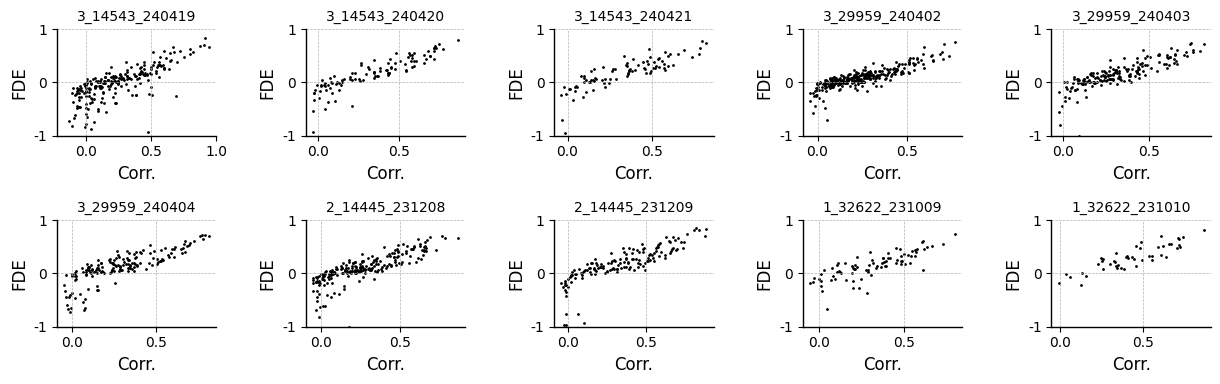

In [ ]:
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        axes[ii,jj].scatter(transformer_results['corr_all'][session_name], transformer_results['fde_all'][session_name], color='k', s=1)
        axes[ii,jj].set_ylim(-1.0, 1)
        axes[ii,jj].set_xlabel('Corr.')
        axes[ii,jj].set_ylabel('FDE')
        axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
plt.tight_layout()

## Rate map

session_target: Dataset_3_29959_240403


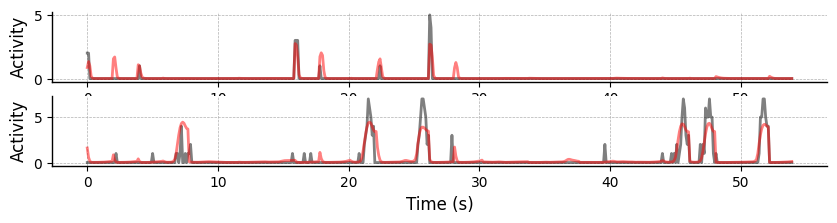

In [16]:
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach()[mask_val == 1.0].cpu().numpy()
            y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() 
            y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
            # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
        X_val_np = np.vstack(X_val_np_list)
        y_val_np = np.vstack(y_val_np_list)
        y_pred_np = np.vstack(y_pred_np_list)
        # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
        temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data

ccs = np.copy(temp_scores)

temps = np.arange(-1, -3, -1).tolist() 
num = y_val_np.shape[0]
nrows = len(temps)
fig, ax = plt.subplots(nrows=nrows, ncols=1, figsize=(10, nrows))
for ii in range(nrows):
    temp = np.argsort(ccs)[temps[ii]]
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_val_np[:num, temp], color='k', alpha=0.5)
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_pred_np[:num,temp], color='red', alpha=0.5)
    ax[ii].set_xlabel("Time (s)") 
    ax[ii].set_ylabel("Activity")

In [17]:
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        mask_val_list = []
        flight_path_index_list = []
        flight_type_index_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach().cpu().numpy()
            y_val_np = y_val.detach().cpu().numpy() 
            y_pred_np = y_pred.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
            flight_path_index_np = batch.flight_path_index.detach().cpu().numpy()
            flight_type_index_np = batch.flight_type_index.detach().cpu().numpy()
            #
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
            mask_val_list.append(mask_val_np)
            flight_path_index_list.append(flight_path_index_np)
            flight_type_index_list.append(flight_type_index_np)
X_val_np = np.vstack(X_val_np_list)
y_val_np = np.vstack(y_val_np_list)
y_pred_np = np.vstack(y_pred_np_list)
mask_val = np.vstack(mask_val_list)
flight_path_index = np.hstack(flight_path_index_list) # use hstack for stacking 1D arrays
flight_type_index = np.hstack(flight_type_index_list) # use hstack for stacking 1D arrays
print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}, y_pred_np.shape: {y_pred_np.shape}, mask_val.shape: {mask_val.shape}')
# X_val_np.shape: (64, 68, 3), y_val_np.shape: (64, 68, 168), y_pred_np.shape: (64, 68, 168), mask_val.shape: (64, 68),... 64 batches, 68 time points, 168 neurons
print(f'flight_path_index.shape: {flight_path_index.shape}, flight_type_index.shape: {flight_type_index.shape}') # flight_path_index.shape: (64,), flight_type_index.shape: (64,)
print(f'flight_path_index: {flight_path_index}')
print(f'flight_type_index: {flight_type_index}')

session_target: Dataset_3_29959_240403
X_val_np.shape: (20, 73, 3), y_val_np.shape: (20, 73, 191), y_pred_np.shape: (20, 73, 191), mask_val.shape: (20, 73)
flight_path_index.shape: (20,), flight_type_index.shape: (20,)
flight_path_index: [ 34.  15.  36. 103.   0.  56.  11.  42.  84.  63.  10.  33. 121.  68.
  76.  81. 102.  93.  57.   5.]
flight_type_index: [ 3.  3.  3. 27.  1. 13.  3.  3. 27. 17.  3.  3. 31. 17. 23. 25. 27. 27.
 14.  3.]


session_target: Dataset_3_29959_240403


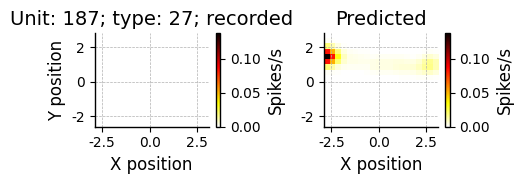

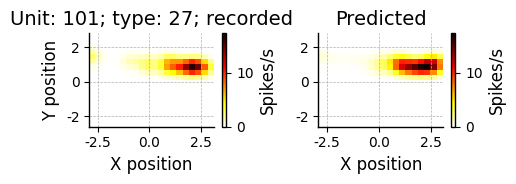

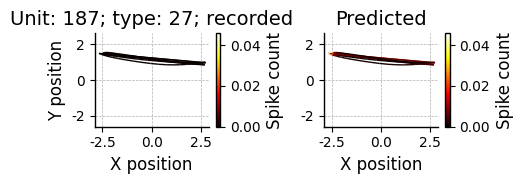

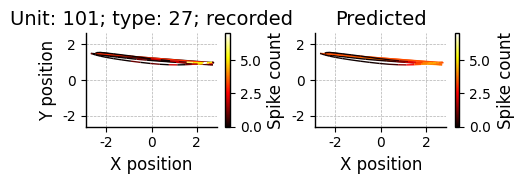

In [18]:
print(f'session_target: {session_target}')
target_type = 27
target_ind = np.where(flight_type_index == target_type)[0]
#
target_X_val = X_val_np[target_ind, :, :]
target_y_val = y_val_np[target_ind, :, :]
target_y_pred = y_pred_np[target_ind, :, :]
target_mask_val = mask_val[target_ind, ]
#
target_X_val = target_X_val[target_mask_val == 1.0]
target_y_val = target_y_val[target_mask_val == 1.0]
target_y_pred = target_y_pred[target_mask_val == 1.0]
# print(f'target_X_val.shape: {target_X_val.shape}, target_y_val.shape: {target_y_val.shape}, target_y_pred.shape: {target_y_pred.shape}')
# target_X_val.shape: (1512, 3), target_y_val.shape: (1512, 168), target_y_pred.shape: (1512, 168) # 168 neurons
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
loc_bin_width = 0.3 # the bin width for the location space
dt = np.copy(data_config['bin_width'])  # time interval for each data point (in seconds)
#
units = np.argsort(ccs)[-2:][::-1]
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_rate_map(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
        loc_bin_width=loc_bin_width,
        dt=dt,
    )
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_trajectory_response(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
    )

# Attention matrix

session_target: Dataset_3_29959_240403


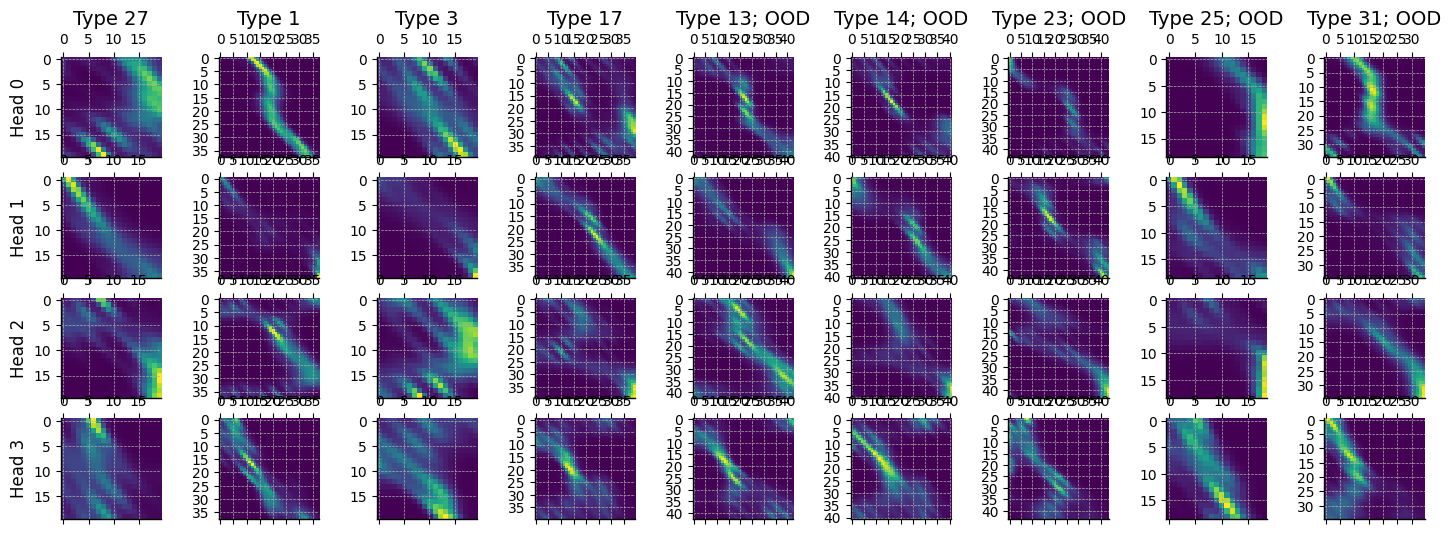

In [19]:
# Show attention weights for each flight cluster type within test data
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            y_pred, attn_weights_list = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
                return_attn_weights=True,
            )
            X_val_np = X_val.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
attn_weights_list = [attn_weights.detach().cpu().numpy() for attn_weights in attn_weights_list]
target_types_indomain = np.array(meta_info_dict['flight_type_test_indomain'][session_target], dtype=int)
target_types_ood = np.array(meta_info_dict['flight_type_test_ood'][session_target], dtype=int)
target_types = np.concatenate((target_types_indomain, target_types_ood))

if True:
    nrows = attn_weights_list[0].shape[1]
    ncols = len(target_types_indomain) + len(target_types_ood)
    np.random.seed(1000)
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*1.5))
    for ii in range(nrows):
        for jj in range(ncols):
            batch_ind, head_ind = np.where(flight_type_index == target_types[jj])[0][0], ii
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            # plt.imshow(attn_weights_list[0][10,1])
            ax[ii,jj].matshow(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        ax[ii,0].set_ylabel(f'Head {ii}')
    for jj in range(ncols):
        ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

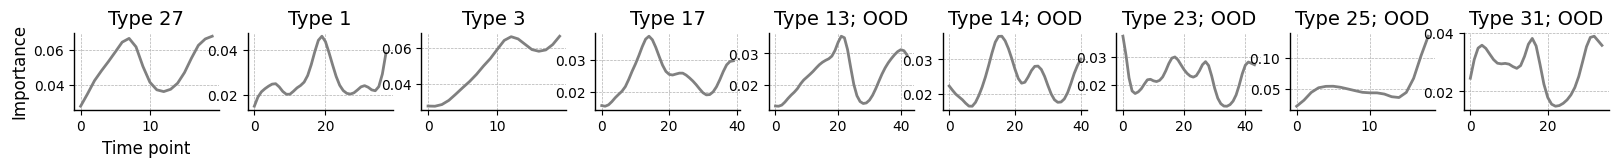

In [20]:
# For each attention matrix, we aggregate weights over the query axis and compute an importance score per time point
# that reflects its overall influence on the model's internal representation (i.e., how strongly the model attends to each position).
# we normalize the score by the length of the query (each flight path) and n_head
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.2, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            temps.append(np.sum(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T], axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


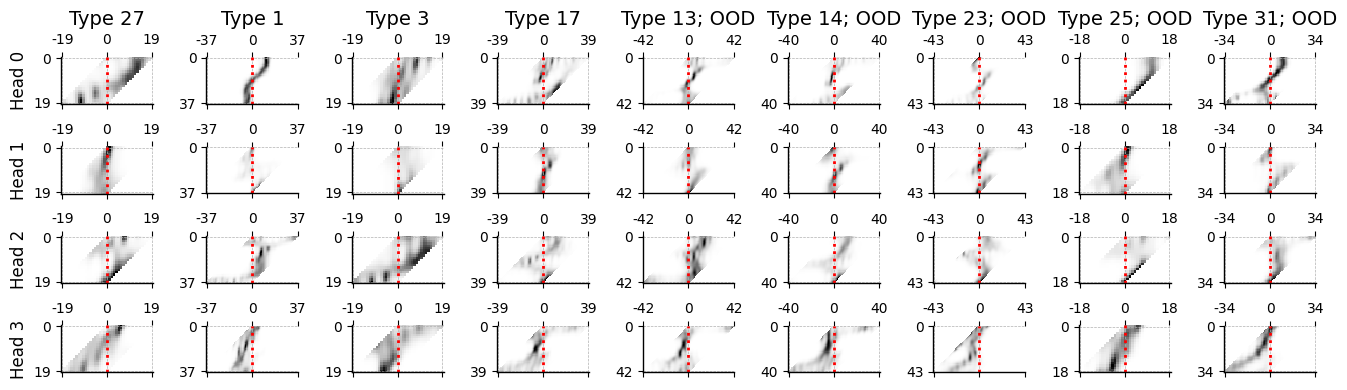

In [21]:
# For each time point, we reindex the attention matrix by a specific temporal offset relative to the query position, 
# producing a time-lag importance profile that quantifies how strongly each position attends to the past, present, and future. 
# This transformation enables direct comparison of temporal dependencies across all positions in the sequence.
from digitalbat.utility.utils import compute_shift_attention
print(f'session_target: {session_target}')
nrows = attn_weights_list[0].shape[1]
ncols = len(target_types)
np.random.seed(1000)
# batch_inds = np.where(flight_type_index==unique_flight_types[temp_ind])[0] # np.random.randint(0, attn_weights_list[0].shape[0], size = ncols)
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*1.5, nrows*1))
for ii in range(nrows):
    for jj in range(ncols):
        batch_ind, head_ind = np.where(flight_type_index==target_types[jj])[0][0], ii
        # only show the unmask elements (not padding ones)
        unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
        # plt.imshow(attn_weights_list[0][10,1])
        shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        # ax[ii,jj].imshow(np.log10(shift_attn+1e-7), cmap='gray_r')
        ax[ii,jj].matshow(shift_attn, cmap='gray_r')
        ax[ii,jj].axvline(unmask_T-1, color='red', linestyle=':')
        ax[ii,jj].set_yticks([0, shift_attn.shape[0]-1])
        ax[ii,jj].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
        ax[ii,jj].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii,0].set_ylabel(f'Head {ii}')
for jj in range(ncols):
    ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')
plt.tight_layout()

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

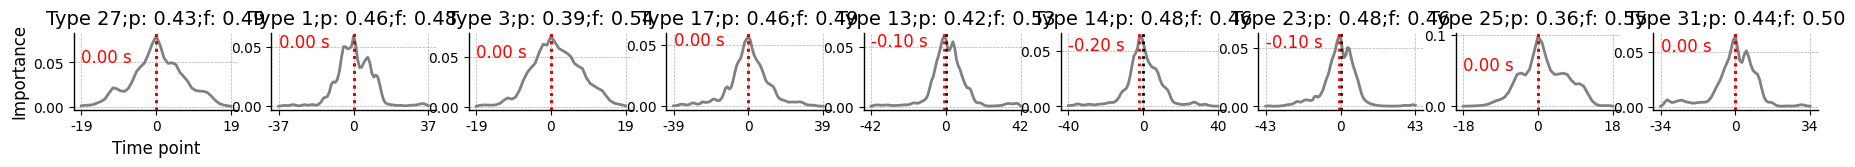

In [22]:
# For each shift attention matrix, we aggregate weights over the query axis and compute an importance score per time point
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn, axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].axvline(unmask_T-1, color='k', linestyle=':')
    ax[ii].axvline(np.argmax(temp), color='red', linestyle=':')
    ax[ii].text(0, 0.05, f"{(np.argmax(temp)-(unmask_T-1)) * data_config['bin_width']:.2f} s", color='red')
    ax[ii].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
    ax[ii].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii].set_title(f'Type {target_types[ii]};p: {np.sum(temp[:unmask_T-1]):.2f};f: {np.sum(temp[unmask_T:]):.2f}')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Query time')

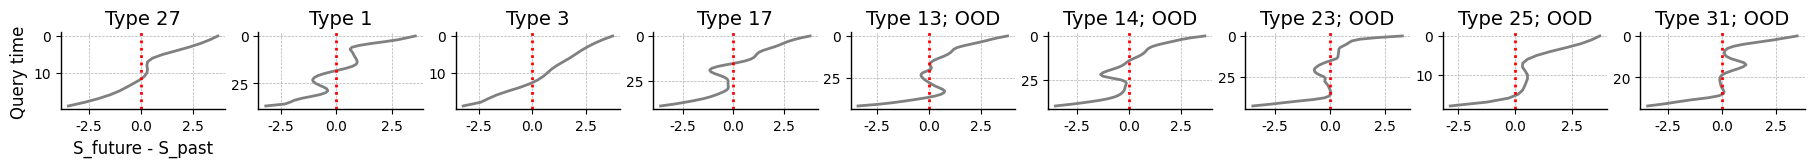

In [23]:
# For each (shift) attention, for each query time position, we aggregate scores over the key axis separately for the past and the future
# and then we subtract the past from the future. At the start of a flight, of course, it only attends to the future. The question is that
# when it starts to attend more to the past.
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].barh(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(temp, np.arange(len(temp)), color='gray')
    ax[ii].invert_yaxis()
    ax[ii].axvline(0.0, color='red', linestyle=':')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('S_future - S_past')
ax[0].set_ylabel('Query time')

session_target: Dataset_3_29959_240403


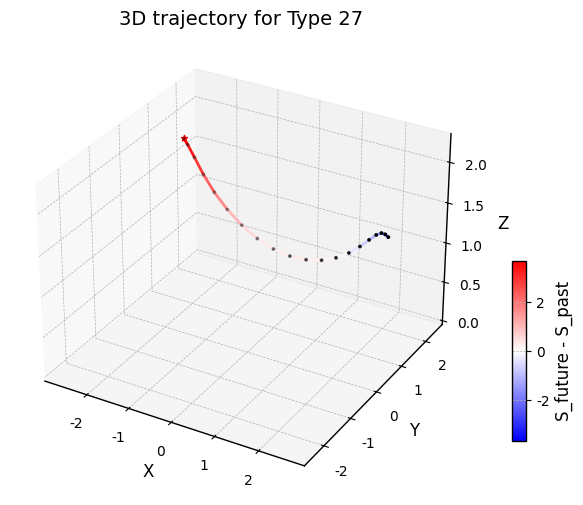

In [24]:
# Plot the 3d trajectory of one flight path (from each flight cluster type), colorized by S_future - S_past 
print(f'session_target: {session_target}')
nheads = attn_weights_list[0].shape[1] # attn_weights_list[0].shape: (64, 4, 68, 68) (batch_size, nheads, T, T)
for ii in range(1): # for ii in range(len(target_types)); for ii in range(1)
    inds = np.where(flight_type_index==target_types[ii])[0]
    for jj in range(1): # for flight paths belong to that type: for jj in range(len(inds)) # for now, we only use one flight path # TODO
        batch_ind = inds[jj]
        temps = []
        for kk in range(nheads): # for each attention head
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val_np, axis=1)[batch_ind]) # mask_val_np.shape: (64, 68) (batch_size, T)
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, kk][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
        s_fut_past = np.sum(np.array(temps), axis=0) # sum across heads 
    
        plot_config = dict(
            # X_val_np.shape: (64, 68, 3) (batch_size, T, 3)
            trajectory_3d = X_val_np[batch_ind][mask_val_np[batch_ind]==1.0,:] * meta_info_dict['behavior_std'][session_target][0,:,:] + meta_info_dict['behavior_mean'][session_target][0,:,:], 
            loc_lim = meta_info_dict['r_lim'][session_target], 
            flight_cluster_type = int(flight_type_index[batch_ind]),
            time_bin_width = data_config['bin_width'],
            visualize_array = s_fut_past, 
            cmap = 'bwr', 
            set_zero_as_medium = True,
            cax_ylabel = 'S_future - S_past', # colorbar ylabel
        )
        plot_3d_trajectory(
            **plot_config
        )

# Saliency

session_target: Dataset_3_29959_240403; target_neuron_index: 20; target_flight_type: 14


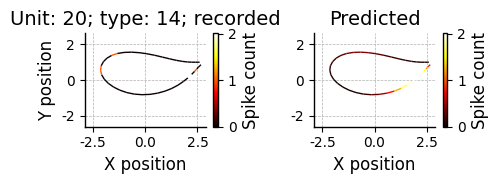

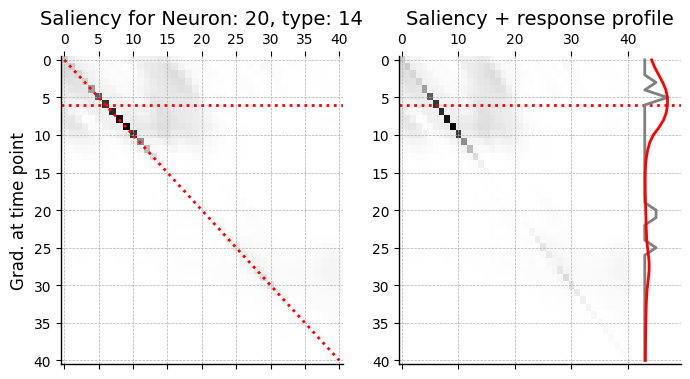

In [25]:
session_target = list(dataloaders['test'].keys())[4] # [4]
target_neuron_index = 20 # 139 # 177
# get the input (flight path) and its mask
target_flight_type = 14 # 32, 23
print(f'session_target: {session_target}; target_neuron_index: {target_neuron_index}; target_flight_type: {target_flight_type}')
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
X_val = X_val[target_flight_index][None, :, :]
y_val = y_val[target_flight_index][None, :, :]
mask_val = mask_val[target_flight_index][None, :]
# model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
# compute gradient
grad_bat_former = Gradient_Bat_Transformer(
    model = bat_former,
    session_name = session_target, 
    X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
    y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
    mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
    target_neuron_index = target_neuron_index,
    trainer_config = trainer_config,
    device = device,
)
grad_bat_former.compute_feature_importance()

target_X_val = grad_bat_former.flight_path
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
spike_count_val = grad_bat_former.response_val
spike_count_pred = grad_bat_former.response_pred
plot_2d_trajectory_response(
    unit=target_neuron_index,
    target_type=target_flight_type,
    loc_xx=loc_xx,
    loc_yy=loc_yy,
    spike_count_val=spike_count_val,
    spike_count_pred=spike_count_pred,
    loc_xx_lim=loc_xx_lim,
    loc_yy_lim=loc_yy_lim,
)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8,4))
axs[0].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[0].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# plt.plot((grad_bat_former.unmask_T, grad_bat_former.unmask_T), (0, grad_bat_former.unmask_T), color='red', linestyle=':')
axs[0].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[0].set_title(f'Saliency for Neuron: {target_neuron_index}, type: {target_flight_type}')
axs[0].set_ylabel('Grad. at time point')

axs[1].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[1].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# axs[1].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[1].set_title(f'Saliency + response profile')
axs[1].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
axs[1].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')

Saliency + response profile: session_target: Dataset_3_29959_240403, target_flight_type: 14


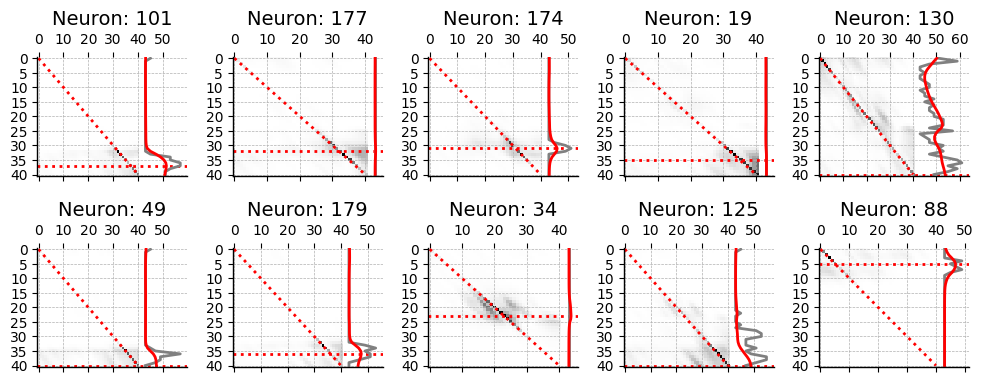

In [26]:
# Show saliency and reponse profiles for multiple neurons during the same flight path
target_flight_type = 14 # 25 # 32, 23
print(f'Saliency + response profile: session_target: {session_target}, target_flight_type: {target_flight_type}')
target_neuron_indices = np.argsort(transformer_results['corr_ood'][session_target])[::-1][:10]
ncols = 5
nrows = int(len(target_neuron_indices)/ncols)
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        target_neuron_index = target_neuron_indices[ii*ncols+jj]

        # get the input (flight path) and its mask
        for session_name, session_data in dataloaders['test'].items():
            # print(session_name, session_data)
            if session_name == session_target:
                # we have only one batch of test data
                for batch_id, batch in enumerate(session_data):
                    X_val = batch[0].to(device)
                    y_val = batch[1].to(device)
                    mask_val = batch[2].to(device)
                    flight_type_index = batch.flight_type_index.detach().cpu().numpy()
                    target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
        X_val = X_val[target_flight_index][None, :, :]
        y_val = y_val[target_flight_index][None, :, :]
        mask_val = mask_val[target_flight_index][None, :]
        # model
        bat_former.load_state_dict(torch.load(model_name, map_location=device))
        # bat_former.load_state_dict(best_weights)
        bat_former = bat_former.to(device)
        bat_former.eval()
        # compute gradient
        grad_bat_former = Gradient_Bat_Transformer(
            model = bat_former,
            session_name = session_target, 
            X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
            y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
            mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
            target_neuron_index = target_neuron_index,
            trainer_config = trainer_config,
            device = device,
        )
        grad_bat_former.compute_feature_importance()
        
        axs[ii,jj].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
        axs[ii,jj].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
        axs[ii,jj].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
        axs[ii,jj].set_title(f'Neuron: {target_neuron_index}')
        axs[ii,jj].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
        axs[ii,jj].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')
plt.tight_layout()

# Hierarchical clustering and orthogonality test

## Analysis

In [27]:
inds_sessions = {} # a dictionary of neuronal indices for each session
pType_sessions = {}  # pType arrays from meta_info_dict, filtered to selected units
readout_weight_sessions = [] # readout weights for selected units from all sessions
for session_target in list(dataloaders['test'].keys()):
    bat_former.load_state_dict(torch.load(model_name, map_location=device))
    bat_former = bat_former.to(device)
    bat_former.eval()
    readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
    n_neurons = readout_weights.shape[0]
    inds = np.arange(n_neurons)
    inds_sessions[session_target] = inds
    pType_sessions[session_target] = np.asarray(meta_info_dict['pType'][session_target])
    readout_weight_sessions.append(readout_weights)
readout_weight_sessions = np.vstack(readout_weight_sessions)
print(f'readout_weight_sessions.shape: {readout_weight_sessions.shape}')

inds_sessions_df = pd.concat(
    [
        pd.DataFrame({
            "session_neuron_idx": inds,
            "session_name": session
        })
        for session, inds in inds_sessions.items()
    ],
    ignore_index=True
)
inds_sessions_df["global_neuron_idx"] = range(len(inds_sessions_df))

# Attach pType (putative cell type)
inds_sessions_df['pType'] = np.concatenate(
    [pType_sessions[s] for s in inds_sessions.keys()]
)

# Attach probe identity
inds_sessions_df['probe_id'] = np.concatenate(
    [meta_info_dict['probe_id'][s] for s in inds_sessions.keys()]
)

# Attach per-neuron metrics from transformer_results
for key in transformer_results:
    inds_sessions_df[key] = np.concatenate(
        [transformer_results[key][s] for s in inds_sessions.keys()]
    )

# Store readout weights (unit-normed) directly in the dataframe
norms = np.linalg.norm(readout_weight_sessions, axis=1, keepdims=True)
readout_normed = readout_weight_sessions / norms
inds_sessions_df['readout_weight'] = list(readout_normed)
inds_sessions_df.loc[inds_sessions_df['pType'].apply(lambda x: isinstance(x, np.ndarray)), 'pType'] = 'filtered'
ct_df = inds_sessions_df[inds_sessions_df['pType'].isin(['pPYR', 'pINT'])].copy()

readout_weight_sessions.shape: (1767, 32)


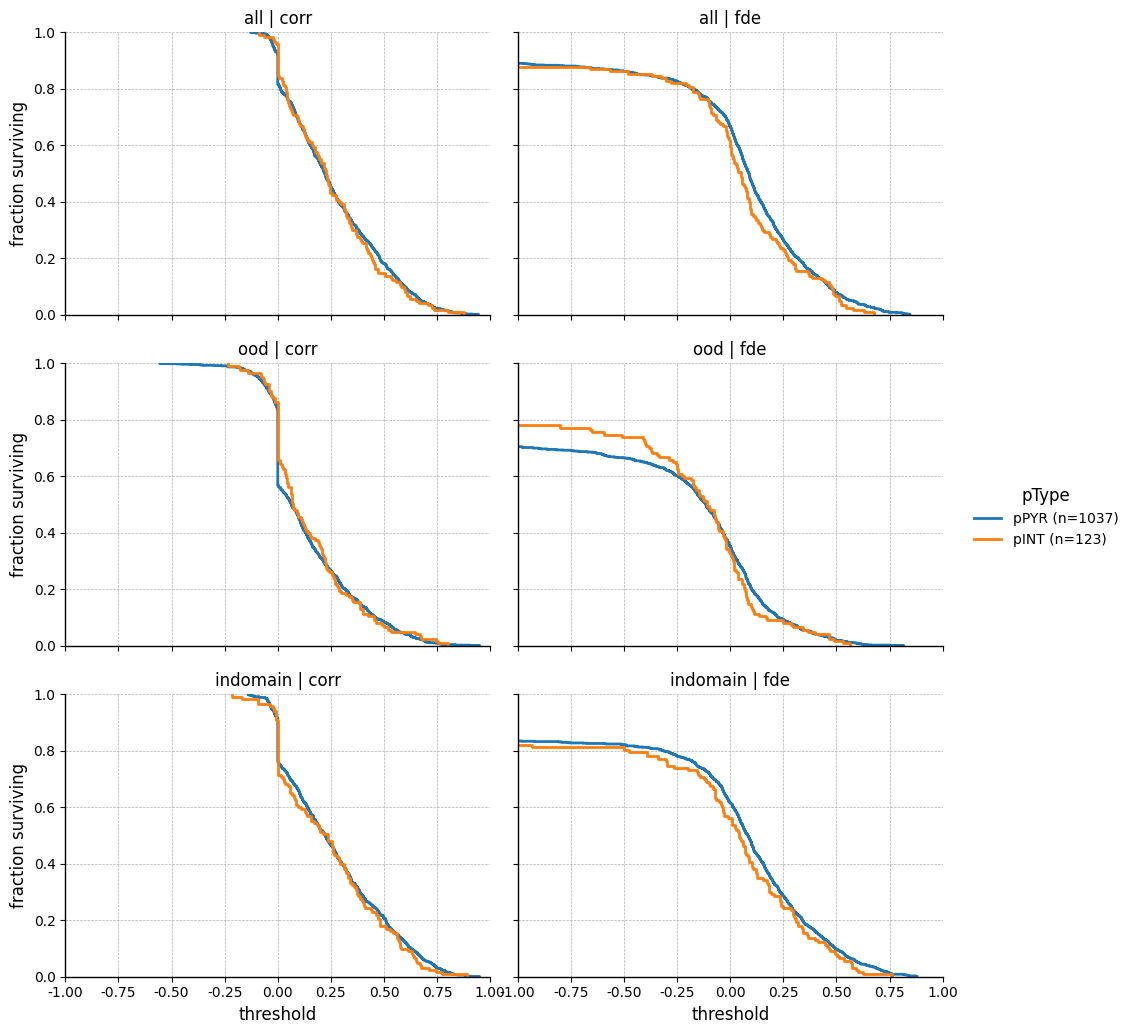

In [28]:
# Fraction of neurons per pType surviving increasing metric thresholds
metric_cols = [c for c in ct_df.columns if c.startswith(('corr_', 'fde_'))]
long_df = ct_df.melt(id_vars='pType', value_vars=metric_cols,
                     var_name='key', value_name='value')
long_df[['metric', 'domain']] = long_df['key'].str.split('_', n=1, expand=True)

# Label pTypes with counts
counts = ct_df['pType'].value_counts()
long_df['pType'] = long_df['pType'].map(lambda p: f'{p} (n={counts[p]})')

# Compute survival fraction via rank
long_df['fraction'] = long_df.groupby(['key', 'pType'])['value'].rank(pct=True)

g = sns.FacetGrid(long_df, row='domain', col='metric',
                  hue='pType', sharey=True, sharex='col',
                  height=3.5, aspect=1.4)
g.map_dataframe(sns.ecdfplot, x='value', complementary=True)
g.add_legend(title='pType')
g.set_axis_labels('threshold', 'fraction surviving')
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
for ax in g.axes.flat:
    ax.set_xlim(left=-1, right=1)


In [29]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

clu_df = inds_sessions_df.loc[inds_sessions_df['corr_all'] > 0.2].copy()
X = np.copy(clu_df['readout_weight'].tolist()) # shape (363, readout_dim)
X = X / np.linalg.norm(X, axis=1, keepdims=True)
# cosine distance = 1 - cosine similarity
dist_condensed = pdist(X, metric="cosine") # shape (363 * 362 / 2,)
dist_matrix = squareform(dist_condensed)  # shape (363, 363)
# Hierarchical clustering
Z = linkage(dist_condensed, method="average")
# The dendrogram returns the leaf order that optimally reflects the hierarchy
dendro = dendrogram(Z, no_plot=True)
order = dendro["leaves"]  # list of reordered neuron indices
# Reorder the distance matrix
dist_matrix_reordered = dist_matrix[np.ix_(order, order)]

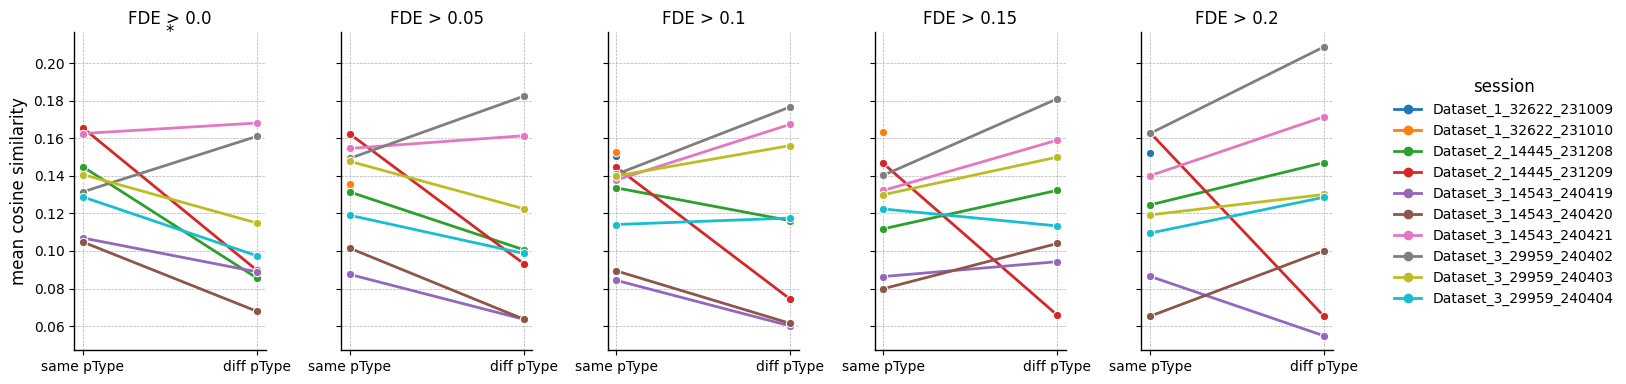

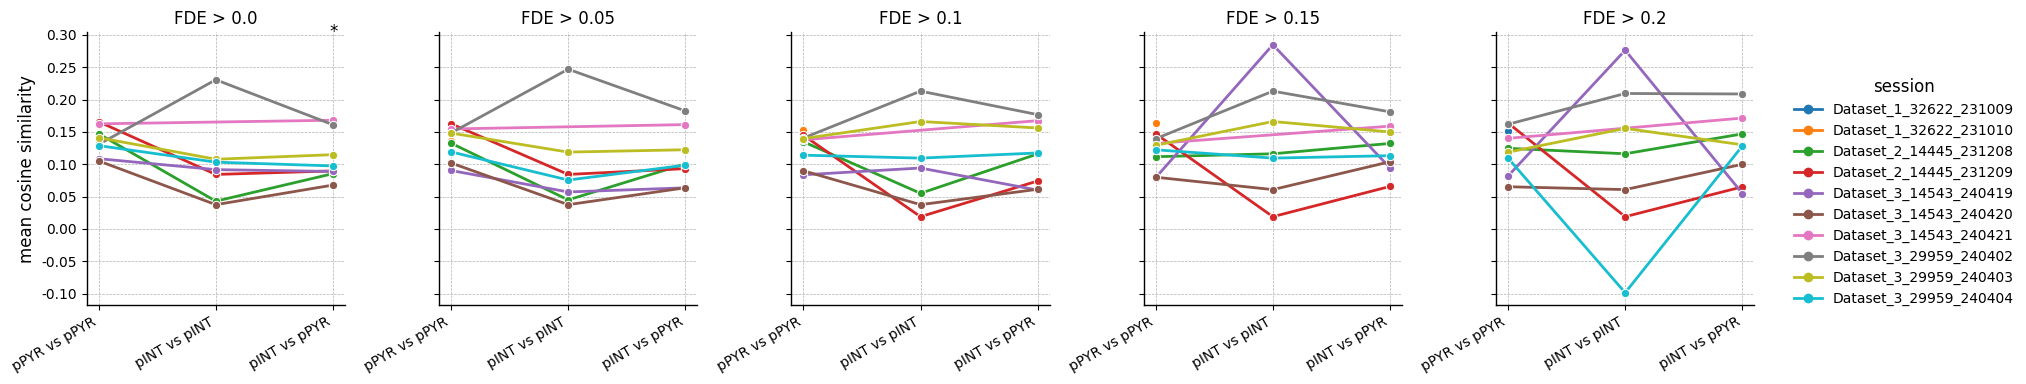

In [30]:
# Pairwise cosine similarity of readout weights, per session and FDE threshold
fde_thresholds = [0, 0.05, 0.1, 0.15, 0.2]
cos_records = []

for fde_thresh in fde_thresholds:
    sub = ct_df[ct_df['fde_all'] > fde_thresh]
    for session_name, grp in sub.groupby('session_name'):
        if len(grp) < 3:
            continue
        W = np.stack(grp['readout_weight'].values)
        cos_sim = W @ W.T
        N = len(grp)
        iu, ju = np.triu_indices(N, k=1)
        pt = grp['pType'].values.astype(str)
        pt_i, pt_j = pt[iu], pt[ju]
        # Canonical pair labels
        lo = np.where(pt_i <= pt_j, pt_i, pt_j)
        hi = np.where(pt_i <= pt_j, pt_j, pt_i)
        pair_label = np.char.add(np.char.add(lo, ' vs '), hi)
        # Same vs diff
        same = pt_i == pt_j
        if same.any():
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison='same pType',
                mean_cosine_sim=cos_sim[iu[same], ju[same]].mean(),
            ))
        if (~same).any():
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison='diff pType',
                mean_cosine_sim=cos_sim[iu[~same], ju[~same]].mean(),
            ))
        # Per-pair breakdown
        for pair in np.unique(pair_label):
            mask = pair_label == pair
            cos_records.append(dict(
                fde_thresh=fde_thresh, session=session_name,
                comparison=pair,
                mean_cosine_sim=cos_sim[iu[mask], ju[mask]].mean(),
            ))

cos_df = pd.DataFrame(cos_records)

# --- Plot 1: same vs diff pType, paired by session ---
cos_same_diff = cos_df[cos_df['comparison'].isin(['same pType', 'diff pType'])]
g = sns.relplot(
    data=cos_same_diff, x='comparison', y='mean_cosine_sim',
    col='fde_thresh', hue='session', kind='line',
    marker='o', height=4, aspect=0.7,
    facet_kws=dict(sharey=True),
)
# Wilcoxon signed-rank test per threshold
for ax, fde_thresh in zip(g.axes.flat, fde_thresholds):
    pivot = (cos_same_diff[cos_same_diff['fde_thresh'] == fde_thresh]
             .pivot(index='session', columns='comparison', values='mean_cosine_sim')
             .dropna())
    if len(pivot) >= 5:
        _, p = wilcoxon(pivot['same pType'], pivot['diff pType'], alternative='greater')
        plot_stars([p], ax, x=[0.5])
g.set_axis_labels('', 'mean cosine similarity')
g.set_titles('FDE > {col_name}')
g.tight_layout()

# --- Plot 2: per-pair breakdown, paired by session ---
pair_names = ['pINT vs pINT', 'pINT vs pPYR', 'pPYR vs pPYR']
cos_pairs = cos_df[cos_df['comparison'].isin(pair_names)]
g2 = sns.relplot(
    data=cos_pairs, x='comparison', y='mean_cosine_sim',
    col='fde_thresh', hue='session', kind='line',
    marker='o', height=4, aspect=0.9,
    facet_kws=dict(sharey=True),
)
# Wilcoxon tests for each within-type vs across-type pair, per threshold
for ax, fde_thresh in zip(g2.axes.flat, fde_thresholds):
    sub = cos_pairs[cos_pairs['fde_thresh'] == fde_thresh]
    pivot = sub.pivot(index='session', columns='comparison', values='mean_cosine_sim').dropna()
    pvals = []
    for pair in pair_names:
        if pair in pivot.columns and 'pINT vs pPYR' in pivot.columns and len(pivot) >= 5:
            if pair == 'pINT vs pPYR':
                pvals.append(1.0)  # reference category
            else:
                _, p = wilcoxon(pivot[pair], pivot['pINT vs pPYR'], alternative='greater')
                pvals.append(p)
        else:
            pvals.append(1.0)
    plot_stars(pvals, ax, x=range(len(pair_names)))
g2.set_axis_labels('', 'mean cosine similarity')
g2.set_titles('FDE > {col_name}')
for ax in g2.axes.flat:
    ax.tick_params(axis='x', rotation=30)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
g2.tight_layout()


## Rate map correlation vs readout weight similarity

In [31]:
# Compute 2D rate maps for all neurons in each session
# Uses observed spike counts (not model predictions)
loc_bin_width_rm = 0.3
dt_rm = data_config['bin_width']

session_rate_maps = {}  # session -> {'all': array(n_neurons, n_flat_bins), 'top_cluster': ...}
session_top_cluster = {}

for session_name, session_data in dataloaders['test'].items():
    X_list, y_list, mask_list, ftype_list = [], [], [], []
    for batch in session_data:
        X_list.append(batch.behavior.numpy())
        y_list.append(batch.spike.numpy())
        mask_list.append(batch.mask.numpy())
        ftype_list.append(batch.flight_type_index.numpy())

    X_all = np.vstack(X_list)
    y_all = np.vstack(y_list)
    mask_all = np.vstack(mask_list)
    ftype_all = np.hstack(ftype_list)
    n_neurons = y_all.shape[2]

    # Denormalize x, y positions
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    loc_xx_lim = meta_info_dict['r_lim'][session_name][0, :]
    loc_yy_lim = meta_info_dict['r_lim'][session_name][1, :]

    # Consistent bin edges for this session
    x_edges = np.arange(loc_xx_lim[0], loc_xx_lim[1] + loc_bin_width_rm, loc_bin_width_rm)
    y_edges = np.arange(loc_yy_lim[0], loc_yy_lim[1] + loc_bin_width_rm, loc_bin_width_rm)
    n_flat = (len(x_edges) - 1) * (len(y_edges) - 1)

    # Most numerous flight cluster
    top_cluster = int(pd.Series(ftype_all).value_counts().index[0])
    session_top_cluster[session_name] = top_cluster

    rate_maps_dict = {}
    for label, flight_mask in [('all', np.ones(len(ftype_all), dtype=bool)),
                               ('top_cluster', ftype_all == top_cluster)]:
        X_sub = X_all[flight_mask]
        y_sub = y_all[flight_mask]
        mask_sub = mask_all[flight_mask]

        # Flatten valid timepoints
        loc_xx = (X_sub[:, :, 0][mask_sub == 1.0] * bs[0, 0, 0] + bm[0, 0, 0])
        loc_yy = (X_sub[:, :, 1][mask_sub == 1.0] * bs[0, 0, 1] + bm[0, 0, 1])
        spikes = y_sub[mask_sub == 1.0]  # (n_valid_timepoints, n_neurons)

        # Occupancy (shared across neurons)
        occupancy, _, _ = np.histogram2d(loc_xx, loc_yy, bins=[x_edges, y_edges])
        occupancy_time = occupancy * dt_rm

        # Rate map per neuron, NaN for unvisited bins
        maps = np.full((n_neurons, n_flat), np.nan)
        for neuron_idx in range(n_neurons):
            spike_map, _, _ = np.histogram2d(
                loc_xx, loc_yy, bins=[x_edges, y_edges],
                weights=spikes[:, neuron_idx],
            )
            with np.errstate(divide='ignore', invalid='ignore'):
                rmap = spike_map / occupancy_time  # NaN where unvisited
            maps[neuron_idx] = rmap.ravel()

        rate_maps_dict[label] = maps

    session_rate_maps[session_name] = rate_maps_dict
    print(f'{session_name}: {n_neurons} neurons, top_cluster={top_cluster}, '
          f'n_bins={n_flat}, n_valid_all={mask_all.sum():.0f}')

Dataset_3_14543_240419: 289 neurons, top_cluster=3, n_bins=360, n_valid_all=199
Dataset_3_14543_240420: 126 neurons, top_cluster=3, n_bins=360, n_valid_all=542
Dataset_3_14543_240421: 100 neurons, top_cluster=23, n_bins=360, n_valid_all=396
Dataset_3_29959_240402: 317 neurons, top_cluster=40, n_bins=360, n_valid_all=574
Dataset_3_29959_240403: 191 neurons, top_cluster=3, n_bins=360, n_valid_all=540
Dataset_3_29959_240404: 190 neurons, top_cluster=1, n_bins=360, n_valid_all=392
Dataset_2_14445_231208: 237 neurons, top_cluster=31, n_bins=608, n_valid_all=591
Dataset_2_14445_231209: 168 neurons, top_cluster=3, n_bins=608, n_valid_all=505
Dataset_1_32622_231009: 95 neurons, top_cluster=15, n_bins=360, n_valid_all=412
Dataset_1_32622_231010: 54 neurons, top_cluster=10, n_bins=360, n_valid_all=458


  Dataset_1_32622_231009 / top_cluster: dropping 3 constant-rate-map neurons
  Dataset_1_32622_231010 / top_cluster: dropping 4 constant-rate-map neurons
  Dataset_2_14445_231208 / top_cluster: dropping 43 constant-rate-map neurons
  Dataset_2_14445_231209 / top_cluster: dropping 5 constant-rate-map neurons
  Dataset_3_14543_240419 / top_cluster: dropping 23 constant-rate-map neurons
  Dataset_3_14543_240420 / top_cluster: dropping 11 constant-rate-map neurons
  Dataset_3_14543_240421 / top_cluster: dropping 4 constant-rate-map neurons
  Dataset_3_29959_240402 / top_cluster: dropping 17 constant-rate-map neurons
  Dataset_3_29959_240403 / top_cluster: dropping 10 constant-rate-map neurons
  Dataset_3_29959_240404 / top_cluster: dropping 8 constant-rate-map neurons
flight_subset                session        r      p  n_neurons  n_pairs  n_shared_bins
          all Dataset_1_32622_231009 0.352950 0.0002         57     1596            134
          all Dataset_1_32622_231010 0.386666 0.0

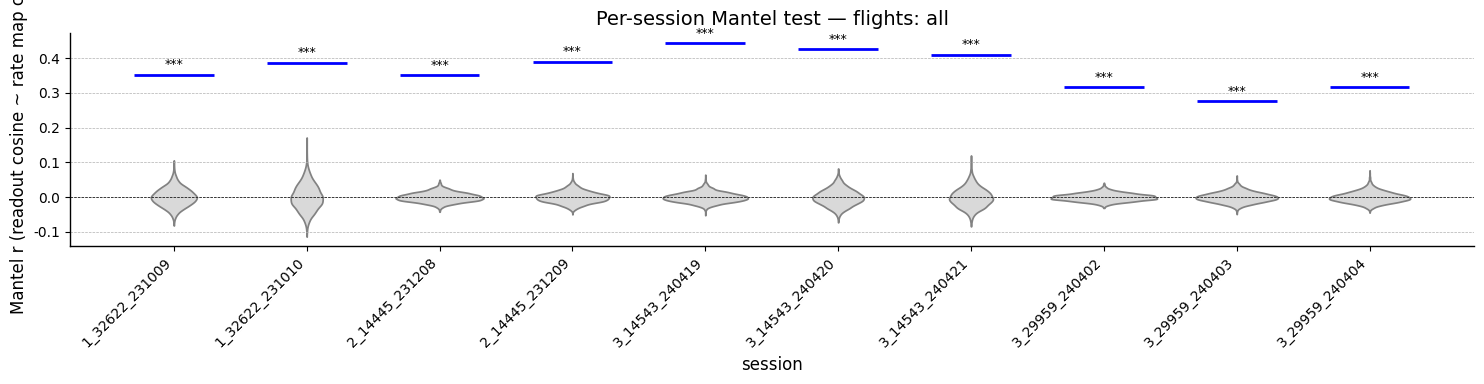

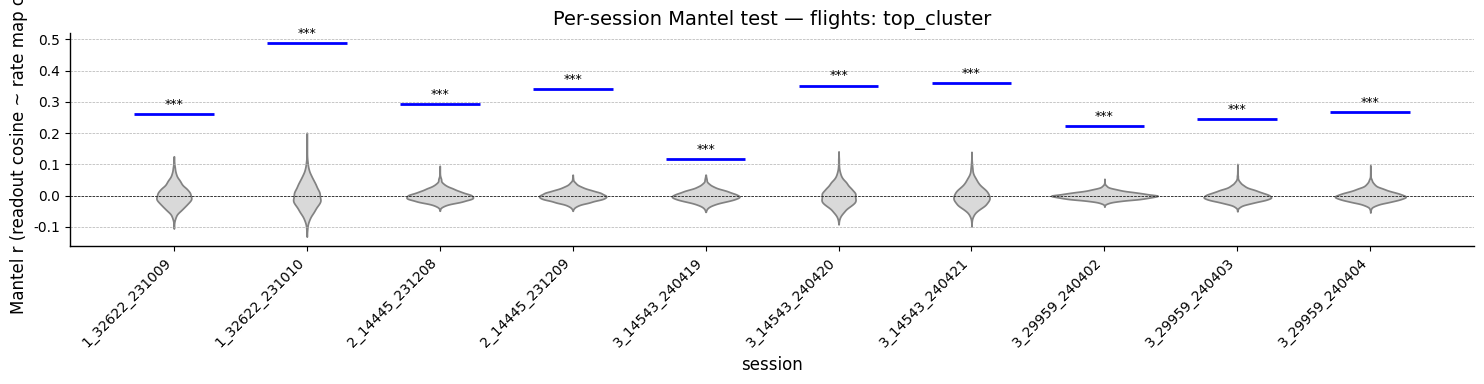

In [32]:
# Compare rate map correlation matrix with readout weight cosine similarity
# Per-session Mantel test, then pooled across sessions

n_mantel_perms = 5000
rng = np.random.default_rng(42)

mantel_records = []
pooled_readout = {fl: [] for fl in ['all', 'top_cluster']}
pooled_ratemap = {fl: [] for fl in ['all', 'top_cluster']}
session_blocks = {fl: [] for fl in ['all', 'top_cluster']}

for flight_label in ['all', 'top_cluster']:
    for session_name, grp in clu_df.groupby('session_name'):
        if len(grp) < 3:
            continue
        neuron_idxs = grp['session_neuron_idx'].values
        N = len(grp)
        iu, ju = np.triu_indices(N, k=1)

        # Rate maps for selected neurons, keep only bins valid for ALL neurons
        maps = session_rate_maps[session_name][flight_label][neuron_idxs]
        shared_valid_bins = ~np.any(np.isnan(maps), axis=0)
        maps_clean = maps[:, shared_valid_bins]
        if maps_clean.shape[1] < 5:
            print(f'  Skipping {session_name} / {flight_label}: only {maps_clean.shape[1]} shared valid bins')
            continue

        # Drop neurons with zero variance (constant rate map) — they produce NaN correlations
        neuron_var = np.var(maps_clean, axis=1)
        has_variance = neuron_var > 0
        if has_variance.sum() < 3:
            print(f'  Skipping {session_name} / {flight_label}: only {has_variance.sum()} neurons with non-constant rate maps')
            continue
        if not has_variance.all():
            print(f'  {session_name} / {flight_label}: dropping {(~has_variance).sum()} constant-rate-map neurons')
        maps_clean = maps_clean[has_variance]
        # Update N and neuron subset for readout weights
        grp = grp.iloc[has_variance]
        N = len(grp)
        iu, ju = np.triu_indices(N, k=1)

        # Pairwise Pearson correlation of rate maps (no NaNs now)
        rate_corr = np.corrcoef(maps_clean)  # (N, N)

        # Readout weight cosine similarity
        W = np.stack(grp['readout_weight'].values)
        cos_sim = W @ W.T

        rc_vec = rate_corr[iu, ju]
        cs_vec = cos_sim[iu, ju]

        # Observed matrix correlation
        r_obs = np.corrcoef(cs_vec, rc_vec)[0, 1]

        # Mantel test: permute neuron labels within session
        perm_rs = np.empty(n_mantel_perms)
        for pi in range(n_mantel_perms):
            perm = rng.permutation(N)
            rc_perm = rate_corr[np.ix_(perm, perm)][iu, ju]
            perm_rs[pi] = np.corrcoef(cs_vec, rc_perm)[0, 1]
        p_mantel = (np.sum(perm_rs >= r_obs) + 1) / (n_mantel_perms + 1)

        mantel_records.append(dict(
            flight_subset=flight_label,
            session=session_name,
            r=r_obs,
            p=p_mantel,
            n_neurons=N,
            n_pairs=len(rc_vec),
            n_shared_bins=int(shared_valid_bins.sum()),
            perm_rs=perm_rs,
        ))

        pooled_readout[flight_label].append(cs_vec)
        pooled_ratemap[flight_label].append(rc_vec)
        session_blocks[flight_label].append(dict(
            N=N, rate_corr=rate_corr, cos_sim=cos_sim,
        ))

mantel_df = pd.DataFrame(mantel_records)
print(mantel_df.drop(columns='perm_rs').to_string(index=False))

# --- Per-session: violin of null distribution + observed r as horizontal line ---
for flight_label in ['all', 'top_cluster']:
    sub = mantel_df[mantel_df['flight_subset'] == flight_label].reset_index(drop=True)
    if sub.empty:
        continue
    perm_rows = []
    for _, row in sub.iterrows():
        short_name = row['session'][8:]
        for rv in row['perm_rs']:
            perm_rows.append(dict(session=short_name, r=rv))
    perm_df = pd.DataFrame(perm_rows)

    fig, ax = plt.subplots(figsize=(max(6, len(sub) * 1.5), 4))
    sns.violinplot(data=perm_df, x='session', y='r', color='0.85',
                   inner=None, cut=0, ax=ax)
    for i, row in sub.iterrows():
        ax.hlines(row['r'], i - 0.3, i + 0.3, color='blue', linewidth=2)
        star = '***' if row['p'] < 0.001 else '**' if row['p'] < 0.01 else '*' if row['p'] < 0.05 else 'n.s.'
        ax.text(i, row['r'] + 0.01, star, ha='center', va='bottom', fontsize=9, color='black')
    ax.set_ylabel('Mantel r (readout cosine ~ rate map corr)')
    ax.set_title(f'Per-session Mantel test — flights: {flight_label}')
    ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
    ax.tick_params(axis='x', rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    plt.tight_layout()

# # --- Pooled: concatenate within-session upper triangles, block-Mantel test ---
# for flight_label in ['all', 'top_cluster']:
#     if not pooled_readout[flight_label]:
#         print(f'No sessions with valid data for pooled {flight_label}')
#         continue
#     cs_pooled = np.concatenate(pooled_readout[flight_label])
#     rc_pooled = np.concatenate(pooled_ratemap[flight_label])
#     r_pooled = np.corrcoef(cs_pooled, rc_pooled)[0, 1]

#     # Block-Mantel: permute neuron labels independently within each session
#     blocks = session_blocks[flight_label]
#     perm_rs_pooled = np.empty(n_mantel_perms)
#     for pi in range(n_mantel_perms):
#         rc_perm_parts = []
#         for blk in blocks:
#             N_blk = blk['N']
#             iu_blk, ju_blk = np.triu_indices(N_blk, k=1)
#             perm = rng.permutation(N_blk)
#             rc_perm_parts.append(
#                 blk['rate_corr'][np.ix_(perm, perm)][iu_blk, ju_blk]
#             )
#         rc_perm_pooled = np.concatenate(rc_perm_parts)
#         perm_rs_pooled[pi] = np.corrcoef(cs_pooled, rc_perm_pooled)[0, 1]
#     p_pooled = (np.sum(perm_rs_pooled >= r_pooled) + 1) / (n_mantel_perms + 1)

#     fig, ax = plt.subplots(figsize=(4, 4))
#     sns.violinplot(y=perm_rs_pooled, color='0.85', inner=None, cut=0, ax=ax)
#     ax.hlines(r_pooled, -0.3, 0.3, color='blue', linewidth=2)
#     star = '***' if p_pooled < 0.001 else '**' if p_pooled < 0.01 else '*' if p_pooled < 0.05 else 'n.s.'
#     ax.text(0, r_pooled + 0.005, f'{star}\nr={r_pooled:.3f}', ha='center', va='bottom',
#             fontsize=9, color='black')
#     ax.set_ylabel('Mantel r')
#     ax.set_title(f'Pooled block-Mantel — flights: {flight_label} (p={p_pooled:.4f})')
#     ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
#     ax.set_xticks([])
#     plt.tight_layout()


In [ ]:
# Plot block-diagonal rate map correlation and readout weight cosine similarity
# Cluster within each session independently, apply that order to both matrices

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import ListedColormap

probe_colors = ['tab:blue', 'tab:orange', 'tab:green']
probe_cmap = ListedColormap(probe_colors)

for flight_label in ['all', 'top_cluster']:
    N_total = len(clu_df)
    rate_corr_block = np.full((N_total, N_total), np.nan)

    # Global reordering: concatenate per-session clustered orders
    global_order = []

    for session_name, grp in clu_df.groupby('session_name'):
        neuron_idxs = grp['session_neuron_idx'].values
        N = len(grp)
        idx = np.where(clu_df['session_name'] == session_name)[0]

        # Rate map correlation
        maps = session_rate_maps[session_name][flight_label][neuron_idxs]
        shared_valid_bins = ~np.any(np.isnan(maps), axis=0)
        maps_clean = maps[:, shared_valid_bins]
        if maps_clean.shape[1] >= 5:
            rc = np.corrcoef(maps_clean)
        else:
            rc = np.full((N, N), np.nan)
        rate_corr_block[np.ix_(idx, idx)] = rc

        # Hierarchical clustering on rate map correlation within this session
        if maps_clean.shape[1] >= 5 and N >= 2:
            rc_clean = np.nan_to_num(rc, nan=0.0)
            dist = 1 - np.abs(rc_clean)
            np.fill_diagonal(dist, 0)
            dist_condensed = squareform(dist, checks=False)
            Z_sess = linkage(dist_condensed, method='average')
            dendro_sess = dendrogram(Z_sess, no_plot=True)
            sess_order = dendro_sess['leaves']
        else:
            sess_order = list(range(N))

        global_order.extend(idx[sess_order])

    global_order = np.array(global_order)
    rate_reordered = rate_corr_block[np.ix_(global_order, global_order)]

    # Full readout weight cosine similarity
    W_all = np.stack(clu_df['readout_weight'].values)
    cos_sim_full = W_all @ W_all.T
    cos_reordered = cos_sim_full[np.ix_(global_order, global_order)]

    # Probe IDs in reordered order
    probe_ids_reordered = clu_df['probe_id'].values[global_order].astype(int)

    vmin, vmax = -1, 1
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for ax, mat, title in zip(axes,
                               [rate_reordered, cos_reordered],
                               [f'Rate map correlation\nflights: {flight_label}',
                                f'Readout weight cosine similarity\nflights: {flight_label}']):
        im = ax.imshow(mat, aspect='auto', cmap='RdBu_r',
                       vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(title)
        ax.set_xlabel('Neuron (clustered within session)')
        ax.set_ylabel('Neuron (clustered within session)')

        # Session boundary lines
        offset = 0
        for session_name, grp in clu_df.groupby('session_name'):
            n = len(grp)
            ax.axhline(offset - 0.5, color='k', linewidth=0.5)
            ax.axvline(offset - 0.5, color='k', linewidth=0.5)
            offset += n

        # Probe color strips as marginal axes
        divider = make_axes_locatable(ax)
        ax_top = divider.append_axes('top', size='2%', pad=0.02)
        ax_right = divider.append_axes('right', size='2%', pad=0.02)

        ax_top.imshow(probe_ids_reordered[None, :], aspect='auto',
                      cmap=probe_cmap, vmin=0, vmax=2, interpolation='nearest')
        ax_top.set_xlim(-0.5, N_total - 0.5)
        ax_top.set_ylim(0.5, -0.5)
        ax_top.axis('off')

        ax_right.imshow(probe_ids_reordered[:, None], aspect='auto',
                        cmap=probe_cmap, vmin=0, vmax=2, interpolation='nearest')
        ax_right.set_xlim(-0.5, 0.5)
        ax_right.set_ylim(N_total - 0.5, -0.5)
        ax_right.axis('off')

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Legend
    for p_id, color in enumerate(probe_colors):
        axes[1].plot([], [], 's', color=color, label=f'Probe {p_id+1}', markersize=6)
    axes[1].legend(loc='upper right', fontsize=8, framealpha=0.8)

    plt.tight_layout()


## Non-flight firing rate correlation

In [ ]:
# --- Cell 1: Load non-flight spike data ---
# Load all spike data (flight + non-flight) and extract non-flight epochs

nonflight_spikes = {}  # session_name -> (n_neurons, n_nonflight_timepoints)

for session_name in data_config['session_names']:
    session_folder = data_config['parent_folder'] + session_name
    su_file_path = data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + session_name + '_with_metrics.mat'

    data_prep = dict(
        parent_folder=session_folder,
        su_file_path=su_file_path,
        use_speed_head_dir=False,
        use_IMU_flag=False,
        use_click_flag=False,
        use_LFP_flag=False,
        use_ripple_flag=False,
        spike_count_flag=data_config['spike_count_flag'],
        bin_width=data_config['bin_width'],
        )

    # Load with only_flight_flag=True to get flight_ind
    dp_flight = Data_Prep_for_Raw(
        only_flight_flag=True,
        **data_prep
    )
    dp_flight.get_all_behavior()
    dp_flight.get_all_spike()
    flight_ind = dp_flight.flight_ind
    n_total_flight = len(dp_flight.all_time_flight)

    # Load with only_flight_flag=False to get all spikes
    dp_all = Data_Prep_for_Raw(
        only_flight_flag=False,
        **data_prep
    )
        
    dp_all.get_all_behavior()
    all_spike = dp_all.get_all_spike()  # (n_neurons, n_total_timepoints)

    # Non-flight indices
    all_ind = np.arange(all_spike.shape[1])
    nonflight_ind = np.setdiff1d(all_ind, flight_ind)
    nonflight_spikes[session_name] = all_spike[:, nonflight_ind]

    print(f'{session_name}: {all_spike.shape[1]} total, {len(flight_ind)} flight, '
          f'{len(nonflight_ind)} non-flight, {all_spike.shape[0]} neurons')


Dataset_3_14543_240419: 52485 total, 1289 flight, 51196 non-flight, 289 neurons
Dataset_3_14543_240420: 50051 total, 3387 flight, 46664 non-flight, 126 neurons
Dataset_3_14543_240421: 55519 total, 2777 flight, 52742 non-flight, 100 neurons
Dataset_3_29959_240402: 45056 total, 4623 flight, 40433 non-flight, 317 neurons
Dataset_3_29959_240403: 46520 total, 3583 flight, 42937 non-flight, 191 neurons
Dataset_3_29959_240404: 45528 total, 2621 flight, 42907 non-flight, 190 neurons
Dataset_2_14445_231208: 51869 total, 3761 flight, 48108 non-flight, 237 neurons
Dataset_2_14445_231209: 48869 total, 3110 flight, 45759 non-flight, 168 neurons
Dataset_1_32622_231009: 67319 total, 2820 flight, 64499 non-flight, 95 neurons
Dataset_1_32622_231010: 66197 total, 3213 flight, 62984 non-flight, 54 neurons


                        comparison                session        r        p  n_neurons  n_pairs
              nonflight vs readout Dataset_1_32622_231009 0.061052 0.136373         57     1596
        nonflight vs ratemap (all) Dataset_1_32622_231009 0.246058 0.000200         57     1596
nonflight vs ratemap (top_cluster) Dataset_1_32622_231009 0.167205 0.000200         54     1431
              nonflight vs readout Dataset_1_32622_231010 0.092151 0.083383         41      820
        nonflight vs ratemap (all) Dataset_1_32622_231010 0.125859 0.001600         41      820
nonflight vs ratemap (top_cluster) Dataset_1_32622_231010 0.080455 0.045991         37      666
              nonflight vs readout Dataset_2_14445_231208 0.190246 0.000200        125     7750
        nonflight vs ratemap (all) Dataset_2_14445_231208 0.234035 0.000200        125     7750
nonflight vs ratemap (top_cluster) Dataset_2_14445_231208 0.258653 0.000200         82     3321
              nonflight vs readout Datas

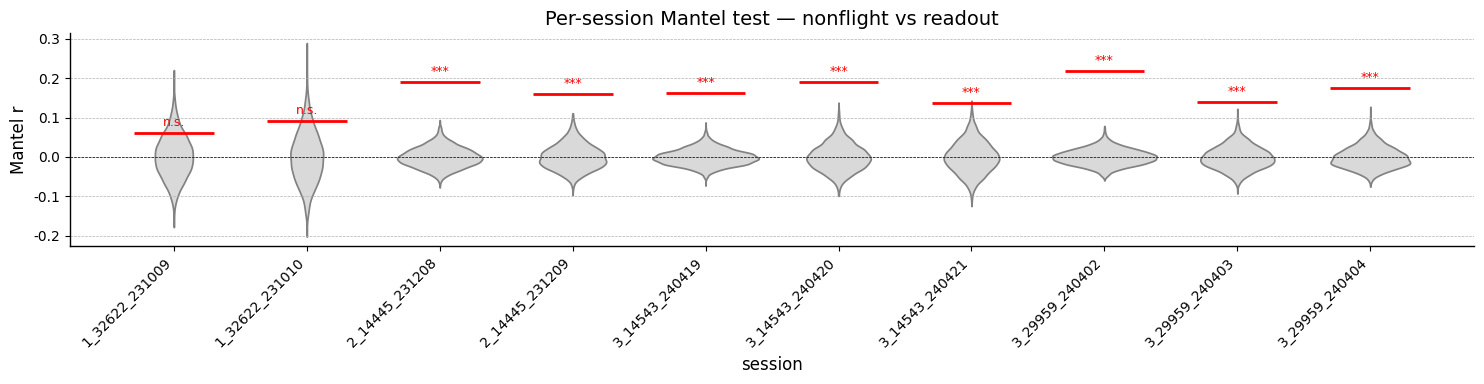

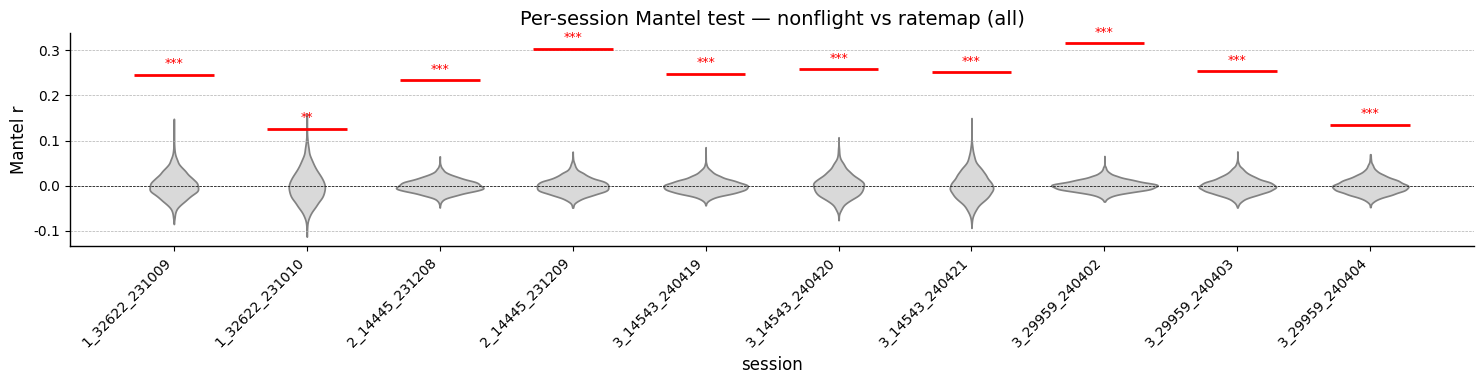

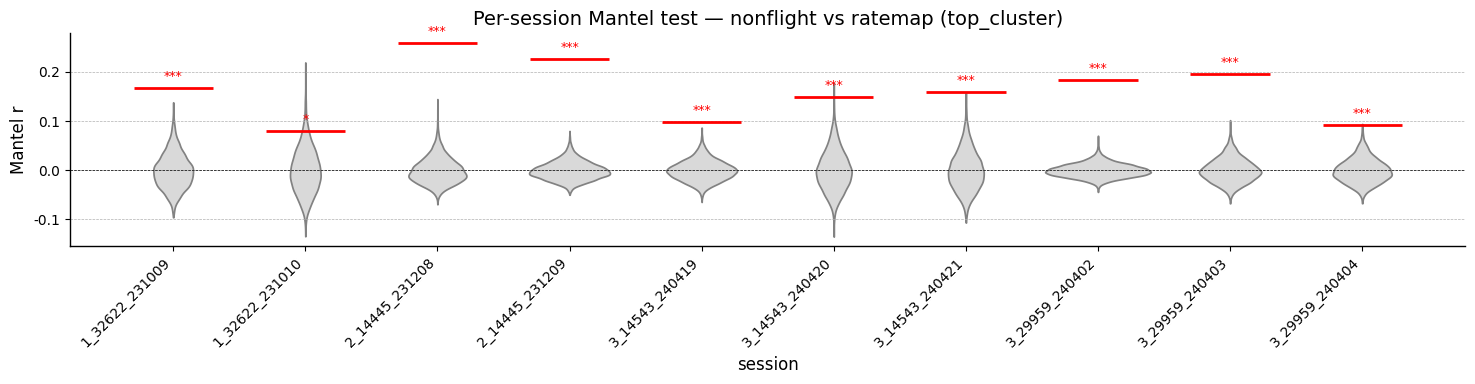

In [ ]:
# Non-flight firing rate correlation vs readout weight cosine similarity and rate map correlation
# Per-session Mantel test + pooled block-Mantel, same structure as flight analysis

n_mantel_perms_nf = 5000
rng_nf = np.random.default_rng(123)

mantel_records_nf = []
pooled_readout_nf = []
pooled_nf_corr = []
pooled_ratemap_nf = {fl: [] for fl in ['all', 'top_cluster']}
session_blocks_nf = []
session_blocks_nf_rm = {fl: [] for fl in ['all', 'top_cluster']}

for session_name, grp in clu_df.groupby('session_name'):
    if len(grp) < 3:
        continue
    neuron_idxs = grp['session_neuron_idx'].values
    N = len(grp)
    iu, ju = np.triu_indices(N, k=1)

    # Non-flight firing rate correlation
    spk = nonflight_spikes[session_name][neuron_idxs, :]  # (N, n_timepoints)
    # Drop neurons with zero variance (silent during non-flight)
    neuron_var = np.var(spk, axis=1)
    has_var = neuron_var > 0
    if has_var.sum() < 3:
        print(f'  Skipping {session_name}: only {has_var.sum()} active neurons in non-flight')
        continue
    if not has_var.all():
        print(f'  {session_name}: dropping {(~has_var).sum()} silent non-flight neurons')
    spk_clean = spk[has_var]
    grp_clean = grp.iloc[has_var]
    N_clean = len(grp_clean)
    iu_c, ju_c = np.triu_indices(N_clean, k=1)

    nf_corr = np.corrcoef(spk_clean)  # (N_clean, N_clean)

    # Readout weight cosine similarity
    W = np.stack(grp_clean['readout_weight'].values)
    cos_sim = W @ W.T

    nf_vec = nf_corr[iu_c, ju_c]
    cs_vec = cos_sim[iu_c, ju_c]

    # --- Mantel: non-flight corr vs readout weights ---
    r_obs = np.corrcoef(cs_vec, nf_vec)[0, 1]
    perm_rs = np.empty(n_mantel_perms_nf)
    for pi in range(n_mantel_perms_nf):
        perm = rng_nf.permutation(N_clean)
        nf_perm = nf_corr[np.ix_(perm, perm)][iu_c, ju_c]
        perm_rs[pi] = np.corrcoef(cs_vec, nf_perm)[0, 1]
    p_mantel = (np.sum(perm_rs >= r_obs) + 1) / (n_mantel_perms_nf + 1)

    mantel_records_nf.append(dict(
        comparison='nonflight vs readout',
        session=session_name,
        r=r_obs,
        p=p_mantel,
        n_neurons=N_clean,
        n_pairs=len(nf_vec),
        perm_rs=perm_rs,
    ))
    pooled_readout_nf.append(cs_vec)
    pooled_nf_corr.append(nf_vec)
    session_blocks_nf.append(dict(N=N_clean, nf_corr=nf_corr, cos_sim=cos_sim))

    # --- Mantel: non-flight corr vs rate map corr (for each flight subset) ---
    for flight_label in ['all', 'top_cluster']:
        neuron_idxs_full = grp['session_neuron_idx'].values
        maps = session_rate_maps[session_name][flight_label][neuron_idxs_full]
        shared_valid = ~np.any(np.isnan(maps), axis=0)
        maps_clean = maps[:, shared_valid]
        # Apply same has_var filter (align neurons)
        maps_clean = maps_clean[has_var]
        map_var = np.var(maps_clean, axis=1) if maps_clean.shape[1] >= 5 else np.zeros(N_clean)
        both_var = (map_var > 0) & (neuron_var[has_var] > 0)
        if both_var.sum() < 3 or maps_clean.shape[1] < 5:
            continue
        if not both_var.all():
            maps_sub = maps_clean[both_var]
            spk_sub = spk_clean[both_var]
            N_sub = int(both_var.sum())
        else:
            maps_sub = maps_clean
            spk_sub = spk_clean
            N_sub = N_clean
        iu_s, ju_s = np.triu_indices(N_sub, k=1)

        rate_corr = np.corrcoef(maps_sub)
        nf_corr_sub = np.corrcoef(spk_sub)
        rm_vec = rate_corr[iu_s, ju_s]
        nf_vec_sub = nf_corr_sub[iu_s, ju_s]

        r_obs_rm = np.corrcoef(rm_vec, nf_vec_sub)[0, 1]
        perm_rs_rm = np.empty(n_mantel_perms_nf)
        for pi in range(n_mantel_perms_nf):
            perm = rng_nf.permutation(N_sub)
            nf_perm = nf_corr_sub[np.ix_(perm, perm)][iu_s, ju_s]
            perm_rs_rm[pi] = np.corrcoef(rm_vec, nf_perm)[0, 1]
        p_rm = (np.sum(perm_rs_rm >= r_obs_rm) + 1) / (n_mantel_perms_nf + 1)

        mantel_records_nf.append(dict(
            comparison=f'nonflight vs ratemap ({flight_label})',
            session=session_name,
            r=r_obs_rm,
            p=p_rm,
            n_neurons=N_sub,
            n_pairs=len(rm_vec),
            perm_rs=perm_rs_rm,
        ))
        pooled_ratemap_nf[flight_label].append(rm_vec)
        session_blocks_nf_rm[flight_label].append(dict(
            N=N_sub, rate_corr=rate_corr, nf_corr=nf_corr_sub,
        ))

mantel_nf_df = pd.DataFrame(mantel_records_nf)
print(mantel_nf_df.drop(columns='perm_rs').to_string(index=False))

# --- Per-session violin plots ---
comparisons = mantel_nf_df['comparison'].unique()
for comp in comparisons:
    sub = mantel_nf_df[mantel_nf_df['comparison'] == comp].reset_index(drop=True)
    if sub.empty:
        continue
    perm_rows = []
    for _, row in sub.iterrows():
        short_name = row['session'][8:]
        for rv in row['perm_rs']:
            perm_rows.append(dict(session=short_name, r=rv))
    perm_df = pd.DataFrame(perm_rows)

    fig, ax = plt.subplots(figsize=(max(6, len(sub) * 1.5), 4))
    sns.violinplot(data=perm_df, x='session', y='r', color='0.85',
                   inner=None, cut=0, ax=ax)
    for i, row in sub.iterrows():
        ax.hlines(row['r'], i - 0.3, i + 0.3, color='red', linewidth=2)
        star = '***' if row['p'] < 0.001 else '**' if row['p'] < 0.01 else '*' if row['p'] < 0.05 else 'n.s.'
        ax.text(i, row['r'] + 0.01, star, ha='center', va='bottom', fontsize=9, color='red')
    ax.set_ylabel('Mantel r')
    ax.set_title(f'Per-session Mantel test — {comp}')
    ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
    ax.tick_params(axis='x', rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    plt.tight_layout()

# # --- Pooled block-Mantel: non-flight vs readout ---
# cs_pooled = np.concatenate(pooled_readout_nf)
# nf_pooled = np.concatenate(pooled_nf_corr)
# r_pooled = np.corrcoef(cs_pooled, nf_pooled)[0, 1]

# perm_rs_pooled = np.empty(n_mantel_perms_nf)
# for pi in range(n_mantel_perms_nf):
#     nf_perm_parts = []
#     for blk in session_blocks_nf:
#         N_blk = blk['N']
#         iu_blk, ju_blk = np.triu_indices(N_blk, k=1)
#         perm = rng_nf.permutation(N_blk)
#         nf_perm_parts.append(blk['nf_corr'][np.ix_(perm, perm)][iu_blk, ju_blk])
#     perm_rs_pooled[pi] = np.corrcoef(cs_pooled, np.concatenate(nf_perm_parts))[0, 1]
# p_pooled = (np.sum(perm_rs_pooled >= r_pooled) + 1) / (n_mantel_perms_nf + 1)

# fig, ax = plt.subplots(figsize=(4, 4))
# sns.violinplot(y=perm_rs_pooled, color='0.85', inner=None, cut=0, ax=ax)
# ax.hlines(r_pooled, -0.3, 0.3, color='red', linewidth=2)
# star = '***' if p_pooled < 0.001 else '**' if p_pooled < 0.01 else '*' if p_pooled < 0.05 else 'n.s.'
# ax.text(0, r_pooled + 0.005, f'{star}\nr={r_pooled:.3f}', ha='center', va='bottom',
#         fontsize=9, color='red')
# ax.set_ylabel('Mantel r')
# ax.set_title(f'Pooled block-Mantel — nonflight vs readout (p={p_pooled:.4f})')
# ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
# ax.set_xticks([])
# plt.tight_layout()

# # --- Pooled block-Mantel: non-flight vs rate map ---
# for flight_label in ['all', 'top_cluster']:
#     if not pooled_ratemap_nf[flight_label]:
#         continue
#     rm_pooled = np.concatenate(pooled_ratemap_nf[flight_label])
#     # Need matching non-flight vectors (same neuron subsets as rate map comparison)
#     nf_pooled_rm = []
#     for blk in session_blocks_nf_rm[flight_label]:
#         N_blk = blk['N']
#         iu_blk, ju_blk = np.triu_indices(N_blk, k=1)
#         nf_pooled_rm.append(blk['nf_corr'][iu_blk, ju_blk])
#     nf_pooled_rm = np.concatenate(nf_pooled_rm)
#     r_pooled_rm = np.corrcoef(rm_pooled, nf_pooled_rm)[0, 1]

#     perm_rs_rm_pooled = np.empty(n_mantel_perms_nf)
#     for pi in range(n_mantel_perms_nf):
#         nf_perm_parts = []
#         for blk in session_blocks_nf_rm[flight_label]:
#             N_blk = blk['N']
#             iu_blk, ju_blk = np.triu_indices(N_blk, k=1)
#             perm = rng_nf.permutation(N_blk)
#             nf_perm_parts.append(blk['nf_corr'][np.ix_(perm, perm)][iu_blk, ju_blk])
#         perm_rs_rm_pooled[pi] = np.corrcoef(rm_pooled, np.concatenate(nf_perm_parts))[0, 1]
#     p_rm_pooled = (np.sum(perm_rs_rm_pooled >= r_pooled_rm) + 1) / (n_mantel_perms_nf + 1)

#     fig, ax = plt.subplots(figsize=(4, 4))
#     sns.violinplot(y=perm_rs_rm_pooled, color='0.85', inner=None, cut=0, ax=ax)
#     ax.hlines(r_pooled_rm, -0.3, 0.3, color='red', linewidth=2)
#     star = '***' if p_rm_pooled < 0.001 else '**' if p_rm_pooled < 0.01 else '*' if p_rm_pooled < 0.05 else 'n.s.'
#     ax.text(0, r_pooled_rm + 0.005, f'{star}\nr={r_pooled_rm:.3f}', ha='center', va='bottom',
#             fontsize=9, color='red')
#     ax.set_ylabel('Mantel r')
#     ax.set_title(f'Pooled block-Mantel — nonflight vs ratemap {flight_label} (p={p_rm_pooled:.4f})')
#     ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
#     ax.set_xticks([])
#     plt.tight_layout()


/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


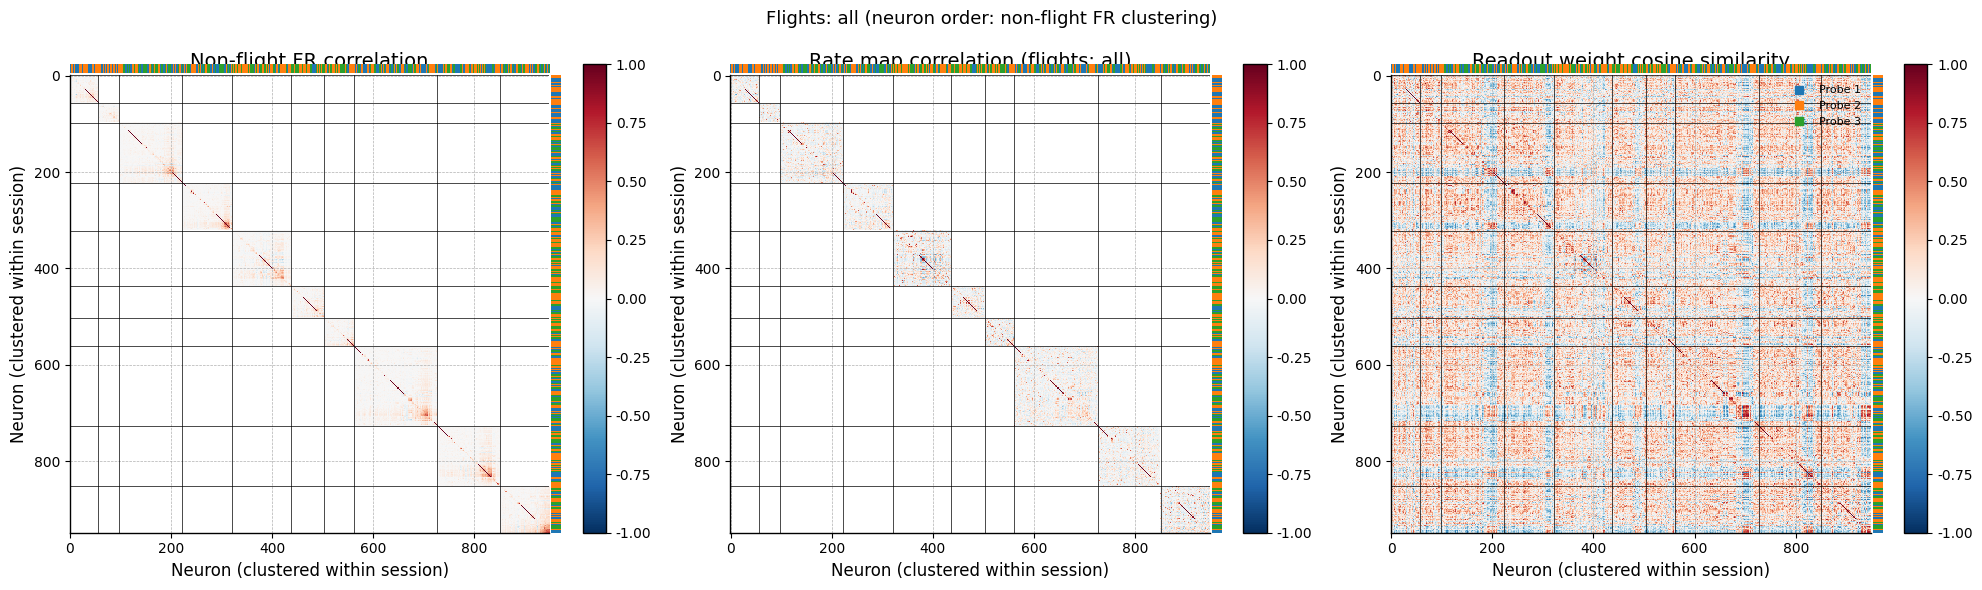

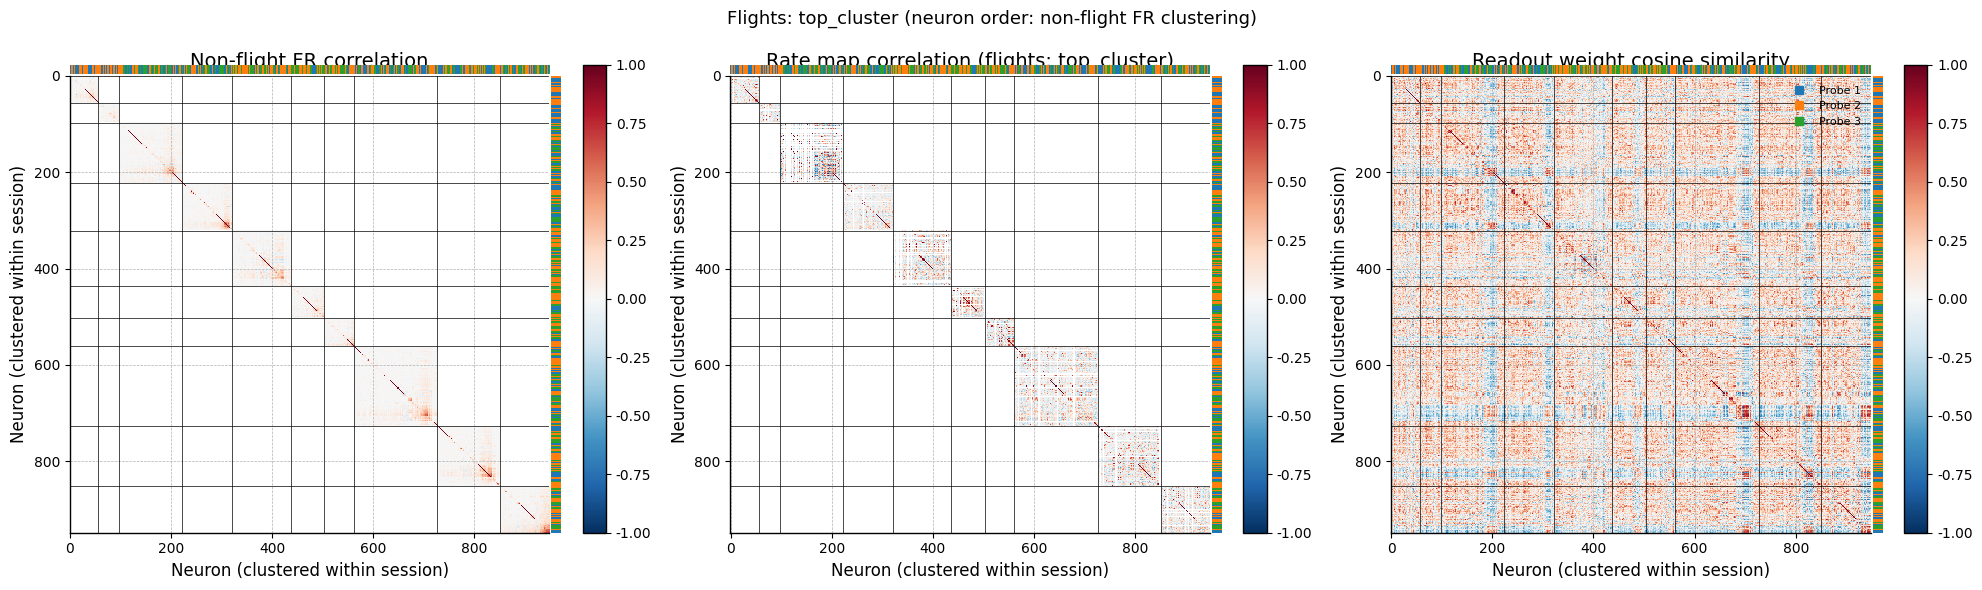

In [47]:
# Plot block-diagonal non-flight FR correlation alongside rate map correlation and readout weights
# Per-session hierarchical clustering on non-flight FR correlation, applied to all three matrices

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import ListedColormap

probe_colors = ['tab:blue', 'tab:orange', 'tab:green']
probe_cmap = ListedColormap(probe_colors)

for flight_label in ['all', 'top_cluster']:
    N_total = len(clu_df)
    nf_corr_block = np.full((N_total, N_total), np.nan)
    rate_corr_block = np.full((N_total, N_total), np.nan)

    global_order = []

    for session_name, grp in clu_df.groupby('session_name'):
        neuron_idxs = grp['session_neuron_idx'].values
        N = len(grp)
        idx = np.where(clu_df['session_name'] == session_name)[0]

        # Non-flight FR correlation
        spk = nonflight_spikes[session_name][neuron_idxs, :]
        spk_var = np.var(spk, axis=1)
        nf_rc = np.corrcoef(spk)
        zero_var = spk_var == 0
        nf_rc[zero_var, :] = np.nan
        nf_rc[:, zero_var] = np.nan
        nf_corr_block[np.ix_(idx, idx)] = nf_rc

        # Rate map correlation
        maps = session_rate_maps[session_name][flight_label][neuron_idxs]
        shared_valid = ~np.any(np.isnan(maps), axis=0)
        maps_clean = maps[:, shared_valid]
        if maps_clean.shape[1] >= 5:
            rm_rc = np.corrcoef(maps_clean)
            map_var = np.var(maps_clean, axis=1)
            rm_rc[map_var == 0, :] = np.nan
            rm_rc[:, map_var == 0] = np.nan
        else:
            rm_rc = np.full((N, N), np.nan)
        rate_corr_block[np.ix_(idx, idx)] = rm_rc

        # Cluster on non-flight FR correlation
        nf_clean = np.nan_to_num(nf_rc, nan=0.0)
        dist = 1 - np.abs(nf_clean)
        np.fill_diagonal(dist, 0)
        if N >= 2:
            dist_condensed = squareform(dist, checks=False)
            Z_sess = linkage(dist_condensed, method='average')
            sess_order = dendrogram(Z_sess, no_plot=True)['leaves']
        else:
            sess_order = list(range(N))
        global_order.extend(idx[sess_order])

    global_order = np.array(global_order)

    # Full readout weight cosine similarity
    W_all = np.stack(clu_df['readout_weight'].values)
    cos_sim_full = W_all @ W_all.T

    nf_reordered = nf_corr_block[np.ix_(global_order, global_order)]
    rm_reordered = rate_corr_block[np.ix_(global_order, global_order)]
    cos_reordered = cos_sim_full[np.ix_(global_order, global_order)]

    # Probe IDs in reordered order
    probe_ids_reordered = clu_df['probe_id'].values[global_order].astype(int)

    vmin, vmax = -1, 1
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    for ax, mat, title in zip(axes,
                               [nf_reordered, rm_reordered, cos_reordered],
                               ['Non-flight FR correlation',
                                f'Rate map correlation (flights: {flight_label})',
                                'Readout weight cosine similarity']):
        im = ax.imshow(mat, aspect='auto', cmap='RdBu_r',
                       vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(title)
        ax.set_xlabel('Neuron (clustered within session)')
        ax.set_ylabel('Neuron (clustered within session)')

        # Session boundary lines
        offset = 0
        for session_name, grp in clu_df.groupby('session_name'):
            n = len(grp)
            ax.axhline(offset - 0.5, color='k', linewidth=0.5)
            ax.axvline(offset - 0.5, color='k', linewidth=0.5)
            offset += n

        # Probe color strips as marginal axes
        divider = make_axes_locatable(ax)
        ax_top = divider.append_axes('top', size='2%', pad=0.02)
        ax_right = divider.append_axes('right', size='2%', pad=0.02)

        ax_top.imshow(probe_ids_reordered[None, :], aspect='auto',
                      cmap=probe_cmap, vmin=0, vmax=2, interpolation='nearest')
        ax_top.set_xlim(-0.5, N_total - 0.5)
        ax_top.set_ylim(0.5, -0.5)
        ax_top.axis('off')

        ax_right.imshow(probe_ids_reordered[:, None], aspect='auto',
                        cmap=probe_cmap, vmin=0, vmax=2, interpolation='nearest')
        ax_right.set_xlim(-0.5, 0.5)
        ax_right.set_ylim(N_total - 0.5, -0.5)
        ax_right.axis('off')

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Legend
    for p_id, color in enumerate(probe_colors):
        axes[2].plot([], [], 's', color=color, label=f'Probe {p_id+1}', markersize=6)
    axes[2].legend(loc='upper right', fontsize=8, framealpha=0.8)

    fig.suptitle(f'Flights: {flight_label} (neuron order: non-flight FR clustering)', fontsize=13)
    plt.tight_layout()


/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/sklearn/metrics

  target                session  bal_acc     kappa   n  n_classes
   pType Dataset_1_32622_231009 0.500000  0.000000  75          2
   pType Dataset_2_14445_231208 0.471131 -0.057738 153          2
   pType Dataset_2_14445_231209 0.489796 -0.020408 103          2
   pType Dataset_3_14543_240419 0.600758  0.201515 172          2
   pType Dataset_3_14543_240420 0.488372 -0.023256  91          2
   pType Dataset_3_29959_240402 0.491500 -0.017001 210          2
   pType Dataset_3_29959_240403 0.529412  0.058824 116          2
   pType Dataset_3_29959_240404 0.496997 -0.006006 120          2
probe_id Dataset_1_32622_231009 0.755583  0.511166  57          2
probe_id Dataset_1_32622_231010 0.482143 -0.035714  41          2
probe_id Dataset_2_14445_231208 0.428641  0.142961 125          3
probe_id Dataset_2_14445_231209 0.391964  0.087946  99          3
probe_id Dataset_3_14543_240419 0.412659  0.118988 115          3
probe_id Dataset_3_14543_240420 0.561636  0.342454  67          3
probe_id D

/tmp/ipykernel_1070454/3278198822.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([s[8:] for s in session_names], rotation=45, ha='right')


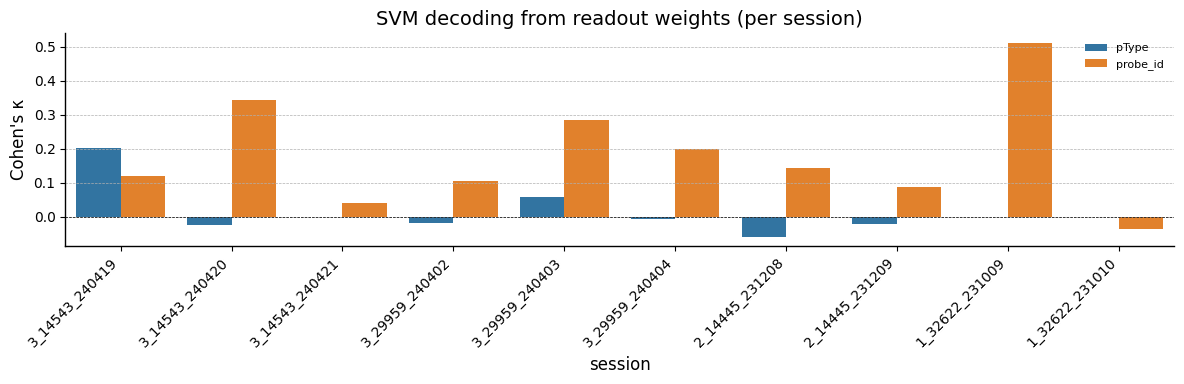

In [53]:
# SVM: predict pType and probe_id from readout weights (nested CV, per session)
# Compare using Cohen's Kappa: κ = (accuracy - chance) / (1 - chance)
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import balanced_accuracy_score

decode_targets = [
    ('pType', ct_df, 'pType'),
    ('probe_id', inds_sessions_df[inds_sessions_df['corr_all'] > 0.2].copy(), 'probe_id'),
]

svm_records = []

for target_name, df, col in decode_targets:
    for session_name, grp in df.groupby('session_name'):
        y = grp[col].values.astype(str)
        unique_labels = sorted(np.unique(y))
        # Need at least 2 classes and enough samples per class for stratified CV
        if len(unique_labels) < 2 or min(np.bincount(pd.factorize(y)[0])) < 3:
            continue
        X = np.stack(grp['readout_weight'].values)
        n_splits = min(10, min(np.bincount(pd.factorize(y)[0])))
        outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        inner_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(kernel='rbf', class_weight='balanced')),
        ])
        param_grid = {'svc__C': np.logspace(-3, 3, 7)}
        nested_clf = GridSearchCV(pipe, param_grid, cv=inner_cv,
                                  scoring='balanced_accuracy', n_jobs=-1)
        y_pred = cross_val_predict(nested_clf, X, y, cv=outer_cv)
        bal_acc = balanced_accuracy_score(y, y_pred)
        chance = 1.0 / len(unique_labels)
        kappa = (bal_acc - chance) / (1.0 - chance)

        svm_records.append(dict(
            target=target_name,
            session=session_name,
            bal_acc=bal_acc,
            kappa=kappa,
            chance=chance,
            n=len(y),
            n_classes=len(unique_labels),
        ))

svm_df = pd.DataFrame(svm_records)
print(svm_df.drop(columns='chance').to_string(index=False))

# Plot Cohen's Kappa per session, grouped by target
fig, ax = plt.subplots(figsize=(max(6, len(svm_df['session'].unique()) * 1.2), 4))
sns.barplot(data=svm_df, x='session', y='kappa', hue='target', ax=ax, order=session_names)
ax.axhline(0, color='k', linewidth=0.5, linestyle='--')
ax.set_xticklabels([s[8:] for s in session_names], rotation=45, ha='right')
ax.set_ylabel("Cohen's κ")
ax.set_title('SVM decoding from readout weights (per session)')
ax.legend(fontsize=8)
plt.tight_layout()


In [ ]:
# plt.figure(figsize=(7, 7))
# im = plt.imshow(dist_matrix_reordered, origin="lower")
# plt.colorbar(im, label="Cosine distance")
# plt.title("Reordered cosine distance matrix (hierarchical clustering)")
# plt.xlabel("Neuron (reordered)")
# plt.ylabel("Neuron (reordered)")
# plt.tight_layout()

In [ ]:
# # plot dendrogram and reordered distance matrix
# fig = plt.figure(figsize=(7, 5))
# # Dendrogram
# ax_dendro = fig.add_axes([0.09, 0.1, 0.2, 0.8])
# dendrogram(
#     Z,
#     orientation="left",
#     # truncate_mode="level",
#     # p=4,                  # show only 4 levels
#     no_labels=True,
#     ax=ax_dendro
# )
# ax_dendro.set_xticks([])
# ax_dendro.set_yticks([])
# # Distance matrix (reordered)
# ax_mat = fig.add_axes([0.3, 0.1, 0.6, 0.8])
# im = ax_mat.matshow(dist_matrix_reordered, aspect="auto", origin="lower")
# ax_mat.set_xticks([])
# ax_mat.set_yticks([])
# # Colorbar
# ax_cb = fig.add_axes([0.92, 0.1, 0.02, 0.8])
# plt.colorbar(im, cax=ax_cb, label="Cosine distance")

In [ ]:
# merge_distances = Z[:, 2]
# plt.figure(figsize=(5, 3))
# plt.plot(np.sort(merge_distances)[::-1])
# plt.xlabel("Merge step (largest → smallest)")
# plt.ylabel("Cosine distance")
# plt.title("Hierarchy merge distances")
# plt.tight_layout()

for t in [0.6, 0.7, 0.8, 0.9, 0.95]:
    n = len(np.unique(fcluster(Z, t, criterion="distance")))
    print(f"t={t}: {n} clusters")

t=0.6: 134 clusters
t=0.7: 68 clusters
t=0.8: 27 clusters
t=0.9: 8 clusters
t=0.95: 4 clusters


Text(0.5, 1.0, 'Cluster sizes (t = 0.9)')

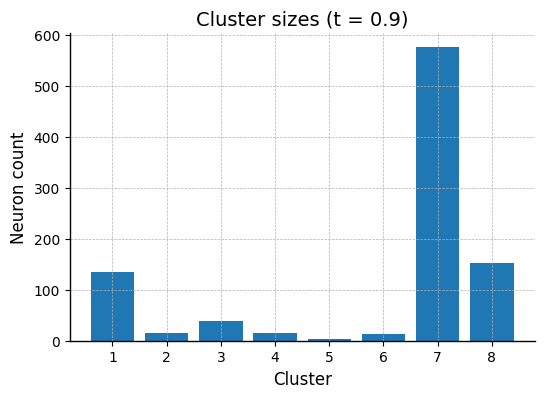

In [ ]:
t_use = 0.9
labels = fcluster(Z, t_use, criterion="distance")
unique, counts = np.unique(labels, return_counts=True)

plt.bar(unique, counts)
plt.xlabel("Cluster")
plt.ylabel("Neuron count")
plt.title(f"Cluster sizes (t = {t_use})")

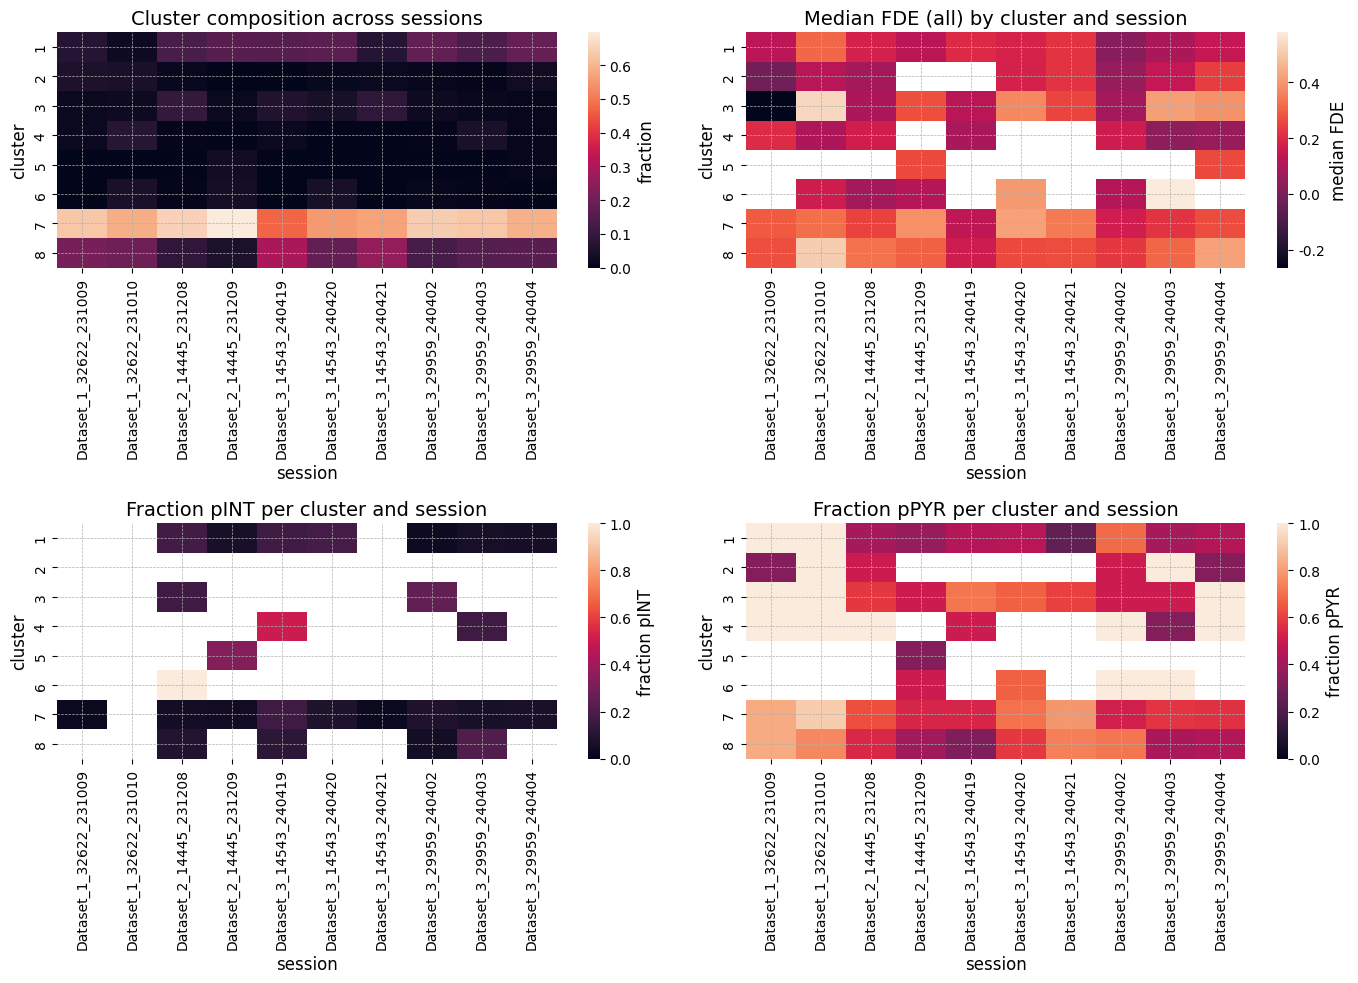

In [ ]:
clu_df["cluster"] = labels
ct = pd.crosstab(clu_df["cluster"], clu_df["session_name"], normalize="columns")

# Median FDE per cluster x session
fde_heatmap = (clu_df.groupby(['cluster', 'session_name'])['fde_all']
               .median().unstack('session_name')
               .reindex(index=ct.index, columns=ct.columns))

# Fraction of pINT / pPYR per cluster x session
ptype_fracs = (clu_df.groupby(['cluster', 'session_name'])['pType']
               .value_counts(normalize=True)
               .unstack('pType'))
ptype_names = ['pINT', 'pPYR']
ptype_heatmaps = {}
for pt in ptype_names:
    ptype_heatmaps[pt] = (ptype_fracs[pt].unstack('session_name')
                          .reindex(index=ct.index, columns=ct.columns))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.heatmap(ct, ax=axes[0, 0], cbar_kws=dict(label='fraction'))
axes[0, 0].set(xlabel='session', ylabel='cluster',
               title='Cluster composition across sessions')

sns.heatmap(fde_heatmap, ax=axes[0, 1], cbar_kws=dict(label='median FDE'))
axes[0, 1].set(xlabel='session', ylabel='cluster',
               title='Median FDE (all) by cluster and session')

for ax, pt in zip(axes[1], ptype_names):
    sns.heatmap(ptype_heatmaps[pt], ax=ax, vmin=0, vmax=1,
                cbar_kws=dict(label=f'fraction {pt}'))
    ax.set(xlabel='session', ylabel='cluster',
           title=f'Fraction {pt} per cluster and session')

plt.tight_layout()


In [ ]:
# Reorder neuron metadata
inds_sessions_df_reordered = inds_sessions_df.iloc[order].reset_index(drop=True)
inds_sessions_df_reordered

,session_neuron_idx,session_name,global_neuron_idx,pType,corr_all,corr_ood,corr_indomain,fde_all,fde_ood,fde_indomain,readout_weight
0,260,Dataset_3_29959_240402,775,unclassified,0.327069,0.298940,0.309716,9.880728e-02,5.695844e-02,6.952602e-02,"[-0.300024, 0.07880628, -0.08343709, -0.128816..."
1,276,Dataset_3_29959_240402,791,filtered,0.049586,0.075021,0.000000,4.032266e-02,1.097124e-01,-5.621936e+33,"[-0.30937758, 0.31671065, -0.11017553, -0.0592..."
2,149,Dataset_3_14543_240419,149,filtered,0.567622,0.000000,0.563079,4.714361e-01,-1.355592e+33,4.842815e-01,"[-0.15280545, -0.13629965, 0.016007928, -0.115..."
3,161,Dataset_3_14543_240419,161,filtered,0.027980,0.195090,0.000000,-2.548945e-01,-4.003025e-01,-1.554150e+33,"[-0.16569704, 0.16357167, -0.06804428, 0.08432..."
4,77,Dataset_3_29959_240402,592,unclassified,0.395161,0.425646,0.407643,1.825385e-01,1.634161e-01,1.841080e-01,"[0.17956862, 0.23693219, -0.123919934, -0.1231..."
...,...,...,...,...,...,...,...,...,...,...,...
944,74,Dataset_3_29959_240402,589,filtered,0.298606,0.301823,0.293012,1.486546e-01,1.540360e-01,6.845838e-02,"[-0.2439771, 0.00686486, -0.12344013, -0.09549..."
945,107,Dataset_3_14543_240420,396,filtered,-0.004401,-0.065257,0.000000,-5.466866e-02,-2.897805e-01,-2.017897e+33,"[-0.20427628, 0.06721341, -0.10777193, -0.1720..."
946,165,Dataset_3_29959_240402,680,pINT,0.229673,0.399702,0.109711,1.303792e-03,1.739663e-01,-1.429263e-01,"[-0.31342438, 0.3140062, -0.38332382, 0.070496..."
947,143,Dataset_3_29959_240402,658,pPYR,0.234297,0.256170,0.232354,4.174250e-02,8.159339e-03,4.352158e-02,"[-0.035008803, -0.091520175, -0.0042522633, 0...."


In [ ]:
tester = OrthogonalityPermutationTest(
    X=readout_weight_sessions,
    df=inds_sessions_df,
    session_name=list(dataloaders['test'].keys())[4],
    n_perm=1000,
    random_state=0,
    null_model='shuffle_weights',
)
sig_df = tester.significant_pairs_with_session_indices(alpha=0.05)
sig_df

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
0,0,21,0.040959,0.991166
1,0,59,0.013986,1.002336
2,0,95,0.044955,0.991040
3,0,180,0.038961,0.986730
4,0,189,0.044955,1.011742
...,...,...,...,...
423,175,187,0.022977,0.993674
424,179,181,0.030969,0.991832
425,179,185,0.046953,0.989755
426,185,188,0.038961,0.990305


In [ ]:
sig_df[sig_df['session_neuron_idx_1'] == 20]

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
80,20,53,0.039960,1.010414
81,20,61,0.030969,0.993594
82,20,72,0.007992,1.002081
83,20,90,0.047952,1.011819
84,20,93,0.001998,1.000436
85,20,155,0.022977,1.005122


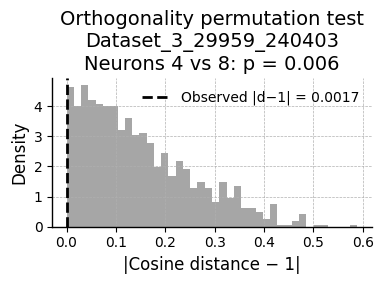

In [ ]:
row = sig_df.iloc[21]
tester.plot_null_vs_observed(
    session_neuron_idx_1=row["session_neuron_idx_1"],
    session_neuron_idx_2=row["session_neuron_idx_2"],
)

# GLM models with 3D cosine basis

Two variants: position-only GLM (lag=0) and GLM with time-lagged positions
(lags from -1.0 to +1.0 s in 0.2 s steps).

In [ ]:
from digitalbat.models.glm import Bat_GLM


def create_cosine_bumps_torch(x, centers, width):
    """Raised cosine bumps in PyTorch.

    x: (...,) tensor of positions
    centers: (K,) tensor of bump centers
    width: scalar bump width

    returns: (..., K) tensor
    """
    diff = x.unsqueeze(-1) - centers
    return (torch.cos(2 * np.pi * diff / width) * 0.5 + 0.5) * (diff.abs() < width / 2).float()


class GLM_3DCosineBasis(nn.Module):
    """3D tensor-product cosine basis expansion + session-wise linear GLM.

    Uses 3D raised cosine bumps over (x, y, z) z-scored position.
    When `lag_seconds` contains multiple values, the design matrix at each
    time step is the concatenation of spatial bases evaluated at the
    corresponding time-lagged positions (zero-padded at sequence edges).

    Parameters
    ----------
    lag_seconds : list of float
        Time offsets (in seconds) at which to evaluate the spatial basis.
        Default ``[0.0]`` gives the position-only GLM.
    bin_width : float
        Temporal bin width in seconds, used to convert lag_seconds to bins.
    """
    def __init__(
        self,
        output_dim_dict,
        n_bases_per_dim=8,
        pos_range=(-3.0, 3.0),
        width_to_spacing_ratio=4,
        activation='exp',
        lag_seconds=None,
        bin_width=0.1,
    ):
        super().__init__()
        if lag_seconds is None:
            lag_seconds = [0.0]
        self.lag_bins = [int(round(s / bin_width)) for s in lag_seconds]
        n_lags = len(self.lag_bins)

        centers = torch.linspace(pos_range[0], pos_range[1], n_bases_per_dim)
        spacing = (pos_range[1] - pos_range[0]) / (n_bases_per_dim - 1)
        self.register_buffer('centers', centers)
        self.width = width_to_spacing_ratio * spacing
        self.n_bases_per_dim = n_bases_per_dim

        n_spatial = n_bases_per_dim ** 3
        self.glm = Bat_GLM(
            input_dim=n_spatial * n_lags,
            output_dim_dict=output_dim_dict,
            activation=activation,
        )
        if n_lags > 1:
            print(f"GLM: {n_lags} lags x {n_spatial} spatial = "
                  f"{n_spatial * n_lags} features, "
                  f"lag_bins={self.lag_bins}")

    def _spatial_basis(self, xyz):
        """Compute 3D tensor-product cosine basis from (N, T, >=3) positions."""
        centers = self.centers.to(xyz.device)
        b_x = create_cosine_bumps_torch(xyz[..., 0], centers, self.width)
        b_y = create_cosine_bumps_torch(xyz[..., 1], centers, self.width)
        b_z = create_cosine_bumps_torch(xyz[..., 2], centers, self.width)
        bases = (
            b_x.unsqueeze(-1).unsqueeze(-1)
            * b_y.unsqueeze(-2).unsqueeze(-1)
            * b_z.unsqueeze(-2).unsqueeze(-2)
        )
        return bases.flatten(-3)  # (N, T, K^3)
    
    def _make_design(self, x, mask=None):
        # x: (N, T, behavior_dim) — first 3 dims = x, y, z (z-scored by dataloader)
        N, T, _ = x.shape
        spatial = self._spatial_basis(x)  # (N, T, K^3)
        K3 = spatial.shape[-1]

        # Zero out spatial basis at invalid (padded) timesteps BEFORE shifting,
        # so that lags reaching into the padded zone get zeros rather than
        # basis values computed from garbage padding data.
        if mask is not None:
            spatial = spatial * mask.unsqueeze(-1)

        lagged = []
        for lag in self.lag_bins:
            if lag == 0:
                lagged.append(spatial)
            elif lag > 0:
                pad = spatial.new_zeros(N, lag, K3)
                lagged.append(torch.cat([spatial[:, lag:, :], pad], dim=1))
            else:
                pad = spatial.new_zeros(N, -lag, K3)
                lagged.append(torch.cat([pad, spatial[:, :T + lag, :]], dim=1))

        return torch.cat(lagged, dim=-1)  # (N, T, K^3 * n_lags)

    def forward(self, session_name, x, mask=None, **kwargs):
        design = self._make_design(x, mask)
        return self.glm(session_name, design)


glm_common = dict(
    output_dim_dict=unit_num_dict,
    n_bases_per_dim=16,
    pos_range=(-3.0, 3.0),
    width_to_spacing_ratio=4,
    activation='exp',
    bin_width=data_config['bin_width'],
)

glm_variants = {
    'GLM': dict(**glm_common),
    'GLM + lags': dict(**glm_common, lag_seconds=np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()),
}

glm_models = {}
for name, cfg in glm_variants.items():
    print(f"\n--- {name} ---")
    glm_models[name] = GLM_3DCosineBasis(**cfg)
    print(glm_models[name])


--- GLM ---
GLM_3DCosineBasis(
  (glm): Bat_GLM(
    (readouts): ModuleDict(
      (Dataset_3_14543_240419): Linear(in_features=4096, out_features=289, bias=True)
      (Dataset_3_14543_240420): Linear(in_features=4096, out_features=126, bias=True)
      (Dataset_3_14543_240421): Linear(in_features=4096, out_features=100, bias=True)
      (Dataset_3_29959_240402): Linear(in_features=4096, out_features=317, bias=True)
      (Dataset_3_29959_240403): Linear(in_features=4096, out_features=191, bias=True)
      (Dataset_3_29959_240404): Linear(in_features=4096, out_features=190, bias=True)
      (Dataset_2_14445_231208): Linear(in_features=4096, out_features=237, bias=True)
      (Dataset_2_14445_231209): Linear(in_features=4096, out_features=168, bias=True)
      (Dataset_1_32622_231009): Linear(in_features=4096, out_features=95, bias=True)
      (Dataset_1_32622_231010): Linear(in_features=4096, out_features=54, bias=True)
    )
  )
)

--- GLM + lags ---
GLM: 11 lags x 4096 spatial = 45

### Visualize 3D cosine basis

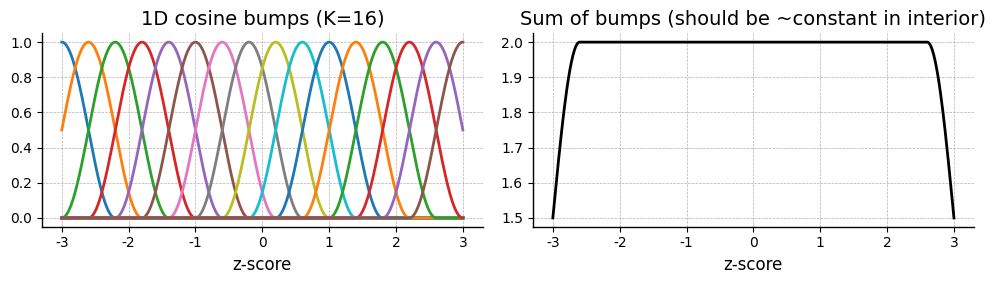

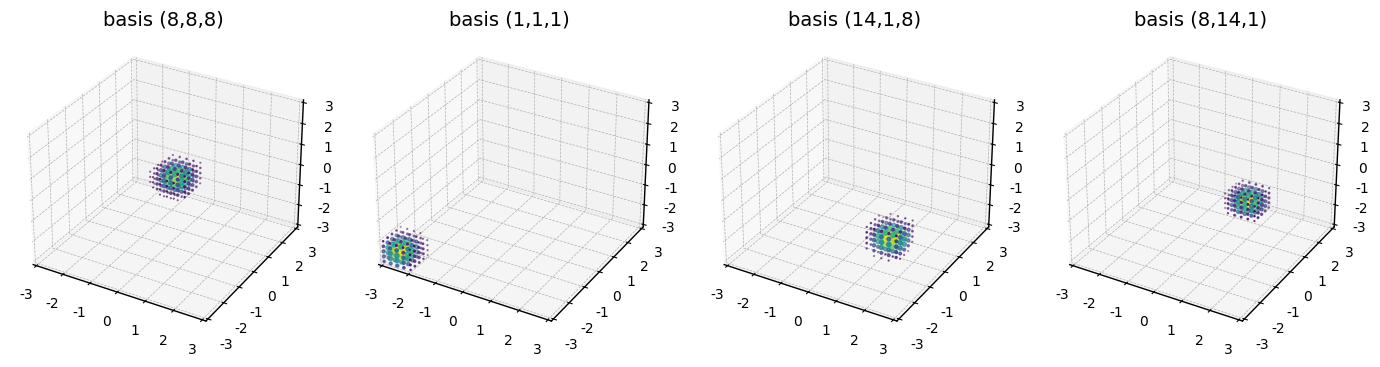

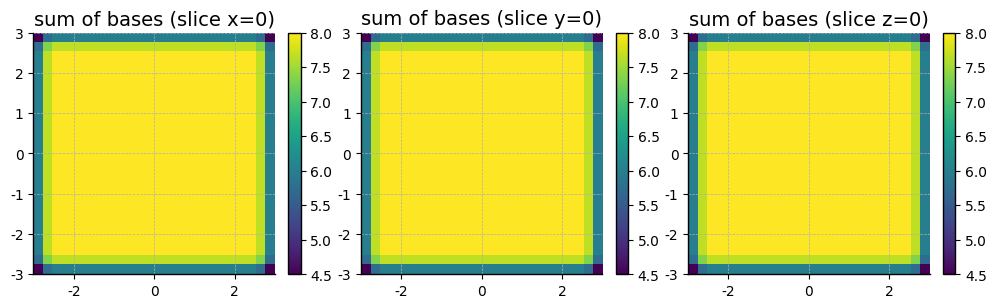

Real positions: shape=(199, 3), x∈[-1.93,1.47], y∈[-1.68,1.04], z∈[-3.62,1.08]


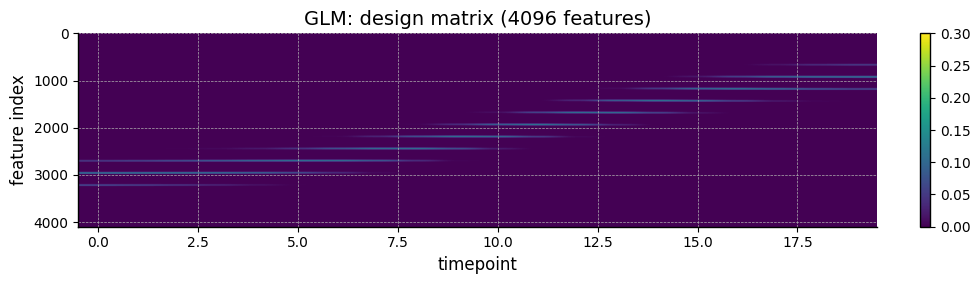

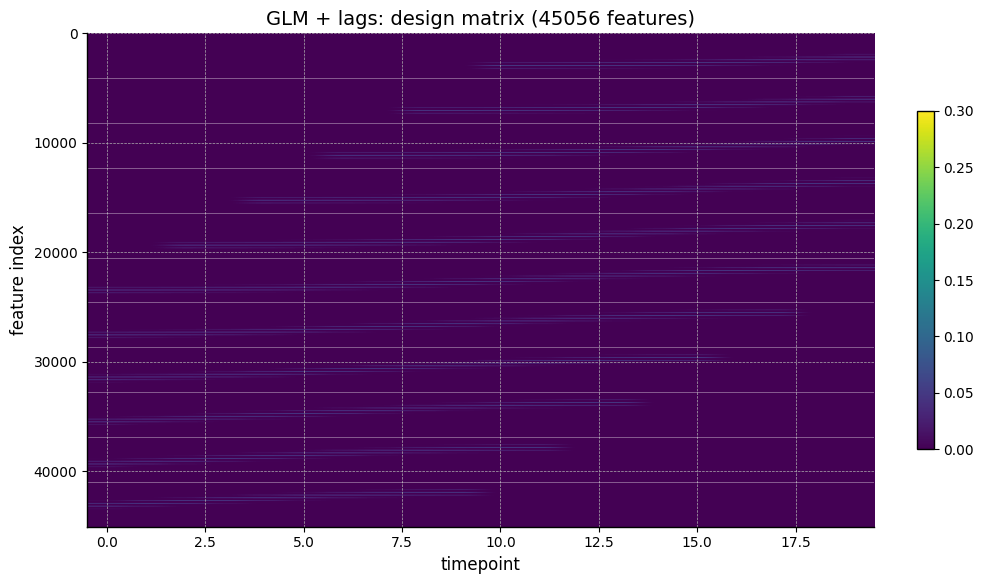

In [ ]:
# Sanity check the 3D raised cosine basis used by the GLM.
# 1) 1D cosine bumps along one axis (should tile evenly — sum ≈ constant in interior).
# 2) A few selected 3D basis functions shown as 3D scatter (point size ∝ basis value).
# 3) Sum-of-bases slices (should be ~constant in the interior of the tiled cube).
# 4) Design matrix on real data for both GLM variants.

centers = glm_models['GLM'].centers.cpu().numpy()
width = glm_models['GLM'].width
K = glm_models['GLM'].n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, glm_models['GLM'].centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout()
plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g, g, g, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], glm_models['GLM'].centers, width)
by = create_cosine_bumps_torch(grid[:, 1], glm_models['GLM'].centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], glm_models['GLM'].centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [
    (K // 2, K // 2, K // 2),
    (1, 1, 1),
    (K - 2, 1, K // 2),
    (K // 2, K - 2, 1),
]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(
        grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
        c=vals[keep], s=20 * vals[keep], cmap='viridis',
    )
    ax.set(title=f'basis ({ix},{iy},{iz})', xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout()
plt.show()

# --- (3) Sum-of-bases slices
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, name in zip(axes, [total[mid], total[:, mid], total[:, :, mid]], ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {name})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# --- (4) Design matrix on real (z-scored) test positions ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
X_real = batch.behavior
mask_real = batch.mask
xyz = X_real[..., :3][mask_real == 1.0]
print(f"Real positions: shape={tuple(xyz.shape)}, "
      f"x∈[{xyz[:,0].min():.2f},{xyz[:,0].max():.2f}], "
      f"y∈[{xyz[:,1].min():.2f},{xyz[:,1].max():.2f}], "
      f"z∈[{xyz[:,2].min():.2f},{xyz[:,2].max():.2f}]")

for i, (name, model) in enumerate(glm_models.items()):
    with torch.no_grad():
        design = model._make_design(X_real, mask_real)

    # Pick one flight, valid timesteps only
    valid = mask_real[0] == 1.0
    design_valid = design[0, valid].cpu().numpy()
    n_features = design_valid.shape[1]

    fig, ax = plt.subplots(figsize=(10, (i+1)*3))
    im = ax.imshow(design_valid.T, aspect='auto', cmap='viridis', vmax=0.3)
    ax.set(xlabel='timepoint', ylabel='feature index',
           title=f'{name}: design matrix ({n_features} features)')
    # Draw lag boundaries if lagged
    n_lags = len(model.lag_bins)
    if n_lags > 1:
        K3 = n_features // n_lags
        for i in range(1, n_lags):
            ax.axhline(i * K3 - 0.5, color='white', lw=0.5, alpha=0.5)
    plt.colorbar(im, ax=ax, fraction=0.02)
    plt.tight_layout()
    plt.show()

## Training


==================== GLM ====================
  Testing weight_decay=0


Training:   9%|▉         | 89/1000 [00:16<02:50,  5.35it/s]


Early stopping at epoch 90 (no improvement for 20 epochs)
    val score: -0.0395
  Testing weight_decay=1e-05


Training:   3%|▎         | 29/1000 [00:06<03:31,  4.58it/s]


Early stopping at epoch 30 (no improvement for 20 epochs)
    val score: -0.0299
  Testing weight_decay=0.0001


...

Early stopping at epoch 21 (no improvement for 20 epochs)
    val score: -0.0298
  Testing weight_decay=1.0


Training:   2%|▏         | 23/1000 [00:04<03:10,  5.13it/s]


Early stopping at epoch 24 (no improvement for 20 epochs)
    val score: -0.0297
  Testing weight_decay=10.0


Training:   2%|▏         | 20/1000 [00:03<02:58,  5.48it/s]

Early stopping at epoch 21 (no improvement for 20 epochs)
    val score: -0.0355
  Best weight_decay: 1.0 (val=-0.0297)


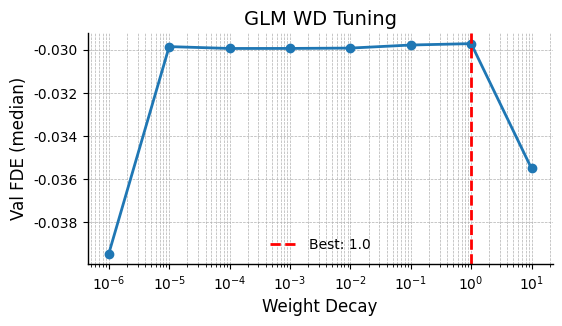


==================== GLM + lags ====================
  Testing weight_decay=0
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


Training:   2%|▎         | 25/1000 [00:06<04:05,  3.97it/s]


Early stopping at epoch 26 (no improvement for 20 epochs)
    val score: -0.0595
  Testing weight_decay=1e-05
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


Training:   2%|▏         | 22/1000 [00:05<04:26,  3.67it/s]

Early stopping at epoch 23 (no improvement for 20 epochs)
    val score: 0.0299
  Testing weight_decay=0.0001
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]


...

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: 0.0238
  Testing weight_decay=1.0
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]



Training:   2%|▏         | 21/1000 [00:05<04:19,  3.77it/s]

Early stopping at epoch 22 (no improvement for 20 epochs)
    val score: 0.0274
  Testing weight_decay=10.0
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]



Training:   3%|▎         | 26/1000 [00:07<04:39,  3.49it/s]


Early stopping at epoch 27 (no improvement for 20 epochs)
    val score: 0.0518
  Best weight_decay: 10.0 (val=0.0518)


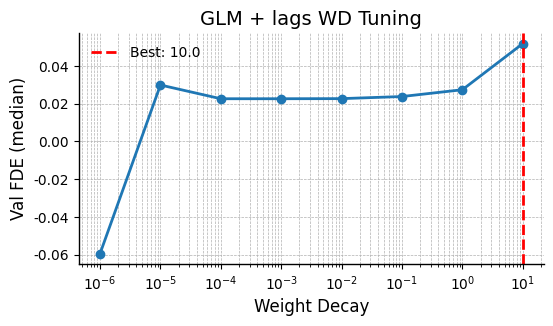

Exception ignored in: <function ResourceTracker.__del__ at 0x7a515e486de0>
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x74228c286de0>
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child 

In [ ]:
# Hyperparameter tuning for weight_decay (both GLM variants)
from copy import deepcopy

weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]

best_wds = {}
for name, cfg in glm_variants.items():
    print(f"\n{'='*20} {name} {'='*20}")
    best_wd_cur, best_val, best_weights_cur = None, -np.inf, None
    wd_results_cur = []

    for wd in weight_decay_candidates:
        print(f'  Testing weight_decay={wd}')
        glm_tune = GLM_3DCosineBasis(**cfg)
        if best_weights_cur is not None:
            glm_tune.load_state_dict(deepcopy(best_weights_cur))
        val_score, weights, _ = bat_former_trainer(
            model=glm_tune, dataloaders=dataloaders, device=device,
            n_epochs=1000, lr=0.01, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=20, save_model=False,
        )
        wd_results_cur.append({'weight_decay': wd, 'val_score': val_score})
        print(f'    val score: {val_score:.4f}')
        if val_score > best_val:
            best_val = val_score
            best_wd_cur = wd
            best_weights_cur = deepcopy(weights)

    best_wds[name] = best_wd_cur
    print(f'  Best weight_decay: {best_wd_cur} (val={best_val:.4f})')

    fig, ax = plt.subplots(figsize=(6, 3))
    wds = [r['weight_decay'] for r in wd_results_cur]
    scores = [r['val_score'] for r in wd_results_cur]
    ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
    ax.axvline(best_wd_cur if best_wd_cur > 0 else 1e-6, color='r', ls='--', label=f'Best: {best_wd_cur}')
    ax.set(xlabel='Weight Decay', ylabel='Val FDE (median)', title=f'{name} WD Tuning')
    ax.legend()
    plt.show()

In [ ]:
# Set best weight decays here if skipping tuning loop
best_wds = {'GLM': 1.0, 'GLM + lags': 10.0}

glm_model_names = {}
for name, cfg in glm_variants.items():
    wd = best_wds[name]
    model_path = f"./out/bat_glm{'_lag' if 'lag' in name else ''}_seed_{seed}_wd_{wd}.pth"
    glm_model_names[name] = model_path

    print(f"\n{'='*20} {name} (wd={wd}) {'='*20}")
    glm_models[name] = GLM_3DCosineBasis(**cfg)

    best_acc, best_weights, acc_vals = bat_former_trainer(
        model=glm_models[name], dataloaders=dataloaders, device=device,
        n_epochs=1000, lr=0.01, weight_decay=wd,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population, valid_stat='median',
        early_stopping_patience=20, save_model=True, model_name=model_path,
    )
    print(f'  Best val score: {best_acc:.4f}')

    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(acc_vals)
    ax.set(title=f"{name}: {best_acc:.4f}", xlabel="Epoch", ylabel="FDE (median)")
    plt.show()


==================== GLM (wd=1.0) ====================


Training:   6%|▋         | 63/1000 [00:12<03:36,  4.34it/s]

## Evaluation

In [ ]:
# Evaluate both GLM variants
all_glm_results = {}
for name, cfg in glm_variants.items():
    model_path = glm_model_names[name]
    glm_models[name].load_state_dict(torch.load(model_path, map_location=device))
    glm_models[name] = glm_models[name].to(device)

    results = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f"{metric_name}_{flight_filter or 'all'}"
            results[key] = evaluate_model(
                glm_models[name], dataloaders, valid_fn, device,
                flight_filter=flight_filter, meta_info_dict=meta_info_dict
            )
            all_scores = np.hstack([v for v in results[key].values() if len(v) > 0])
            stat = np.nanmedian if 'fde' in key else np.nanmean
            print(f"{name} {key}: {stat(all_scores):.4f}")
    all_glm_results[name] = results

# Aliases for backward compatibility with comparison cells
glm_results = all_glm_results['GLM']
glm_lag_results = all_glm_results['GLM + lags']

GLM corr_all: 0.1754
GLM corr_ood: 0.0765
GLM corr_indomain: 0.2157
GLM fde_all: -0.0367
GLM fde_ood: -0.2709
GLM fde_indomain: 0.0020
GLM + lags corr_all: 0.2320
GLM + lags corr_ood: 0.1076
GLM + lags corr_indomain: 0.2705
GLM + lags fde_all: -0.0779
GLM + lags fde_ood: -0.4716
GLM + lags fde_indomain: 0.0004


In [ ]:
# Build comparison DataFrame with all subsets (GLM vs GLM+lags vs Transformer)
rows = []
for session_name in transformer_results['corr_all'].keys():
    bat_id = re.search(r'_(\d{5})_', session_name).group(1)
    date_str = session_name[-6:]
    date = datetime.strptime(date_str, '%y%m%d').date()
    n_units = len(transformer_results['corr_all'][session_name])

    model_results = {
        'GLM': glm_results,
        'GLM + lags': glm_lag_results,
        'Transformer': transformer_results,
    }

    for i in range(n_units):
        for subset in ['all', 'ood', 'indomain']:
            corr_key = f'corr_{subset}'
            fde_key = f'fde_{subset}'
            for model_name_str, results_dict in model_results.items():
                rows.append({
                    'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                    'model': model_name_str, 'metric': 'Correlation', 'subset': subset,
                    'value': results_dict[corr_key][session_name][i]
                })
                rows.append({
                    'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                    'model': model_name_str, 'metric': 'FDE', 'subset': subset,
                    'value': max(results_dict[fde_key][session_name][i], -1)
                })

df = pd.DataFrame(rows)
df

,session,bat,date,unit,model,metric,subset,value
0,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,Correlation,all,-0.013987
1,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,FDE,all,-1.000000
2,Dataset_3_14543_240419,14543,2024-04-19,0,GLM + lags,Correlation,all,-0.011258
3,Dataset_3_14543_240419,14543,2024-04-19,0,GLM + lags,FDE,all,-0.203326
4,Dataset_3_14543_240419,14543,2024-04-19,0,Transformer,Correlation,all,0.330198
...,...,...,...,...,...,...,...,...
31801,Dataset_1_32622_231010,32622,2023-10-10,53,GLM,FDE,indomain,-0.033914
31802,Dataset_1_32622_231010,32622,2023-10-10,53,GLM + lags,Correlation,indomain,0.133154
31803,Dataset_1_32622_231010,32622,2023-10-10,53,GLM + lags,FDE,indomain,-0.007206
31804,Dataset_1_32622_231010,32622,2023-10-10,53,Transformer,Correlation,indomain,0.102416


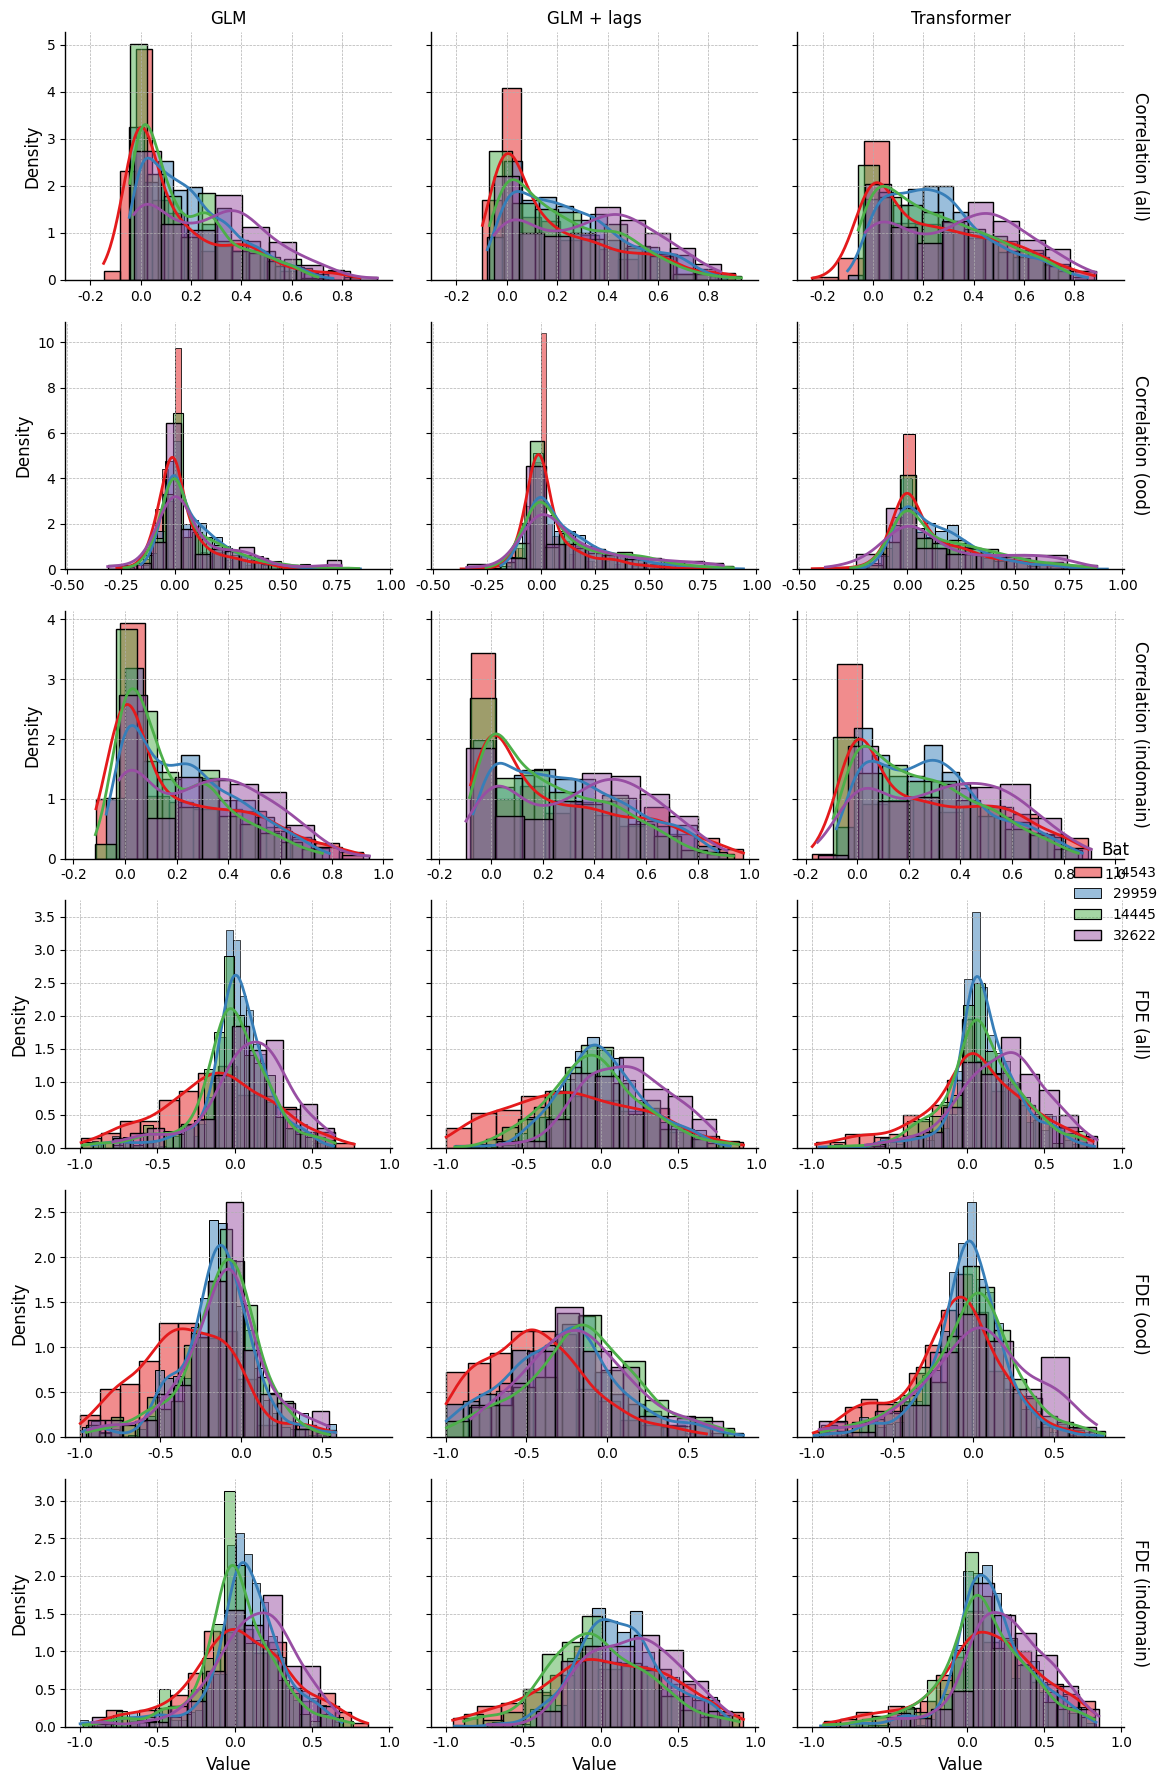

In [ ]:
# Plot all sessions: col=model, row=metric+subset, hue=bat
df['row_label'] = df['metric'] + ' (' + df['subset'] + ')'

row_order = [
    'Correlation (all)', 'Correlation (ood)', 'Correlation (indomain)',
    'FDE (all)', 'FDE (ood)', 'FDE (indomain)'
]

col_order = ['GLM', 'GLM + lags', 'Transformer']

# Filter out FDE values <= -1
df_filtered = df[~((df['metric'] == 'FDE') & (df['value'] <= -1))]

g = sns.FacetGrid(
    df_filtered,
    col='model',
    row='row_label',
    hue='bat',
    col_order=col_order,
    row_order=row_order,
    height=3,
    aspect=1.2,
    palette='Set1',
    sharex='row',
    sharey='row',
    margin_titles=True
)

g.map(sns.histplot, 'value', kde=True, alpha=0.5, stat='density', common_norm=False)
g.set_axis_labels('Value', 'Density')
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.add_legend(title='Bat')
plt.tight_layout()
plt.show()

Wilcoxon signed-rank tests (H1: second model > first model)

==================== Subset: all ====================
--- Correlation ---
  GLM vs GLM + lags: n=1767, median diff=0.0326, p=1.95e-82 ***
  GLM vs Transformer: n=1767, median diff=0.0635, p=2.38e-134 ***
  GLM + lags vs Transformer: n=1767, median diff=0.0093, p=4.04e-14 ***
--- FDE ---
  GLM vs GLM + lags: n=1481, median diff=-0.0068, p=8.98e-01 
  GLM vs Transformer: n=1489, median diff=0.1095, p=9.72e-151 ***
  GLM + lags vs Transformer: n=1581, median diff=0.1150, p=9.39e-107 ***

==================== Subset: ood ====================
--- Correlation ---
  GLM vs GLM + lags: n=1767, median diff=0.0000, p=8.44e-17 ***
  GLM vs Transformer: n=1767, median diff=0.0198, p=4.81e-53 ***
  GLM + lags vs Transformer: n=1767, median diff=0.0000, p=6.10e-19 ***
--- FDE ---
  GLM vs GLM + lags: n=1157, median diff=-0.0966, p=1.00e+00 
  GLM vs Transformer: n=1252, median diff=0.1330, p=7.46e-67 ***
  GLM + lags vs Transformer: n=1224

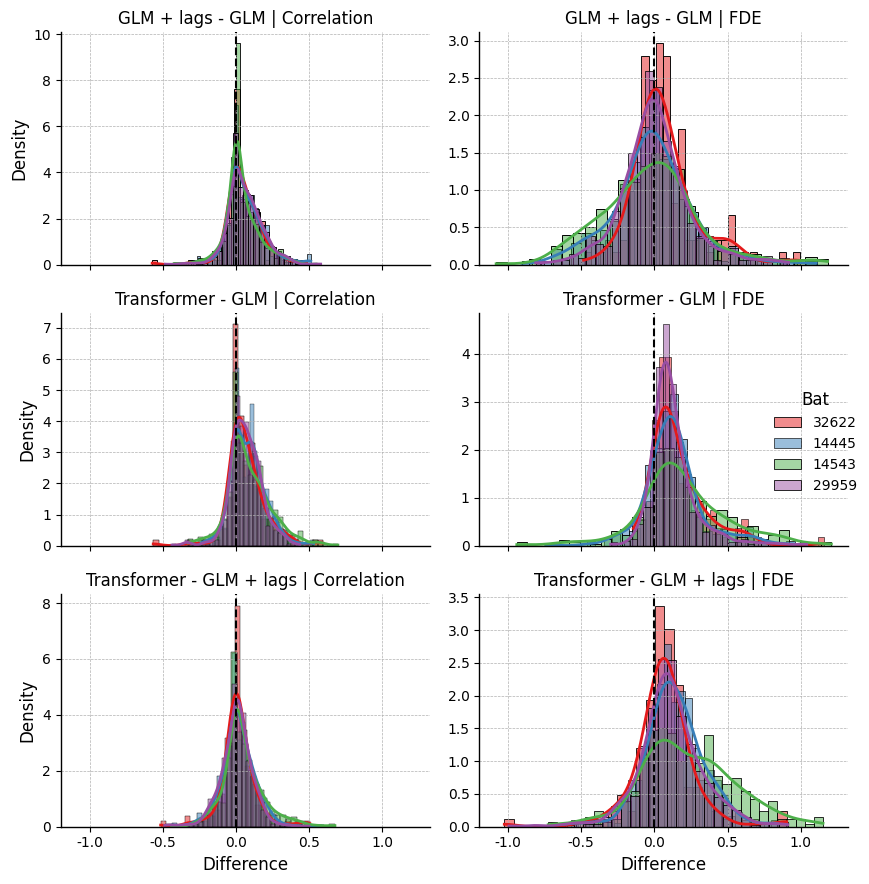

In [ ]:
# Wilcoxon signed-rank tests: pairwise model comparisons (per subset)
def wilcoxon_test(scores_a, scores_b, name):
    """Run Wilcoxon signed-rank test and print results."""
    mask = ~(np.isnan(scores_a) | np.isnan(scores_b))
    a, b = scores_a[mask], scores_b[mask]
    if len(a) < 10:
        print(f"{name}: n={len(a)} (too few samples)")
        return None
    stat, p = wilcoxon(a, b, alternative='less')
    median_diff = np.median(b - a)
    print(f"{name}: n={len(a)}, median diff={median_diff:.4f}, p={p:.2e} "
          f"{'***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''}")
    return {'name': name, 'n': len(a), 'median_diff': median_diff, 'p': p}

model_pairs = [
    ('GLM', 'GLM + lags'),
    ('GLM', 'Transformer'),
    ('GLM + lags', 'Transformer'),
]

print("Wilcoxon signed-rank tests (H1: second model > first model)")
print("=" * 60)

stats_results = []
for subset in ['all', 'ood', 'indomain']:
    print(f"\n{'='*20} Subset: {subset} {'='*20}")
    df_subset = df_filtered[df_filtered['subset'] == subset]

    for metric in ['Correlation', 'FDE']:
        df_metric = df_subset[df_subset['metric'] == metric]
        df_pivot = df_metric.pivot_table(
            index=['session', 'bat', 'date', 'unit'], columns='model', values='value'
        ).reset_index()

        print(f"--- {metric} ---")
        for m_a, m_b in model_pairs:
            result = wilcoxon_test(
                df_pivot[m_a].values, df_pivot[m_b].values, f"  {m_a} vs {m_b}"
            )
            if result:
                stats_results.append({
                    **result, 'metric': metric, 'subset': subset,
                    'comparison': f'{m_a} vs {m_b}'
                })

df_stats = pd.DataFrame(stats_results)
print("\nSummary:")
print(df_stats[['metric', 'subset', 'comparison', 'n', 'median_diff', 'p']].to_string(index=False))

# Histogram of pairwise differences (for 'all' subset)
df_all = df_filtered[df_filtered['subset'] == 'all']

diff_rows = []
for metric in ['Correlation', 'FDE']:
    df_metric = df_all[df_all['metric'] == metric]
    df_pivot = df_metric.pivot_table(
        index=['session', 'bat', 'date', 'unit'], columns='model', values='value'
    ).reset_index()
    for m_a, m_b in model_pairs:
        d = df_pivot[m_b] - df_pivot[m_a]
        for val, bat in zip(d, df_pivot['bat']):
            diff_rows.append({'metric': metric, 'comparison': f'{m_b} - {m_a}', 'diff': val, 'bat': bat})

df_diff = pd.DataFrame(diff_rows)

g = sns.FacetGrid(
    df_diff, col='metric', row='comparison', hue='bat',
    height=3, aspect=1.3, palette='Set1', sharey=False
)
g.map(sns.histplot, 'diff', kde=True, alpha=0.5, stat='density', common_norm=False, bins=30)
for ax in g.axes.flat:
    ax.axvline(0, color='black', linestyle='--', lw=1.5)
g.set_axis_labels('Difference', 'Density')
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.add_legend(title='Bat')
plt.tight_layout()
plt.show()